# Tugas 1 - Prediksi Customer Churn dengan Artificial Neural Network (TensorFlow / Keras)

| Nama | NRP |
|------|-----|
| Kadek Nathania Gavrila Astika | 5054251050 |

## Deskripsi Tugas
Pada tugas ini, kita akan menggunakan Churn Modelling Dataset. Dataset bisa diakses melalui link berikut:\
https://www.kaggle.com/datasets/shrutimechlearn/churn-modelling

Dataset berisi data 10.000 nasabah bank, seperti skor kredit, negara, usia, saldo, dan status keaktifan. Tujuan utama dari tugas ini adalah membangun model Artificial Neural Network (ANN) menggunakan **TensorFlow / Keras** untuk memprediksi apakah seorang nasabah akan berhenti menjadi nasabah (churn, kolom `Exited`) atau tidak.

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi label.
2. Preprocessing
   - Memproses data agar siap digunakan oleh ANN.
3. Eksperimen Model
   - Bangun model baseline Logistic Regression dan beberapa konfigurasi ANN.
4. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
5. Analisis dan Kesimpulan
   - Bandingkan hasil seluruh model dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, tensorflow, dll).
# Set random seed agar hasil eksperimen dapat direproduksi, gunakan tf.keras.utils.set_random_seed(42).
import os
import warnings

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"   # sembunyikan log info TensorFlow
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, roc_curve, roc_auc_score)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Random seed (Python, NumPy, dan TensorFlow sekaligus) agar eksperimen dapat direproduksi
SEED = 42
tf.keras.utils.set_random_seed(SEED)

# Pengaturan tampilan plot (dipakai konsisten di seluruh notebook)
WARNA_KELAS = {0: "#2a78d6", 1: "#eb6834"}            # 0 = bertahan (biru), 1 = churn (oranye)
LABEL_KELAS = {0: "Bertahan (0)", 1: "Churn (1)"}
WARNA_TRAIN, WARNA_VAL = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.labelsize": 10, "legend.frameon": False, "figure.dpi": 110,
})
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

print("TensorFlow :", tf.__version__)
print("Keras      :", keras.__version__)
print("Pandas     :", pd.__version__)
print("NumPy      :", np.__version__)

TensorFlow : 2.21.0
Keras      : 3.15.1
Pandas     : 3.1.0
NumPy      : 2.5.4


In [6]:
# Load dataset dan tampilkan beberapa baris pertama.
# Tampilkan informasi dasar: jumlah baris dan kolom, tipe data, statistik deskriptif, dan jumlah missing value.
df = pd.read_csv("Churn_Modelling.csv")
display(df.head())

print(f"\nJumlah baris: {df.shape[0]:,}")
print(f"Jumlah kolom: {df.shape[1]}")

print("\nTipe data setiap kolom:")
df.info()

print("\nStatistik deskriptif (kolom numerik):")
display(df.describe().T)

print("Statistik deskriptif (kolom kategorikal):")
display(df.describe(include="object").T)

print("Jumlah missing value per kolom:")
display(df.isnull().sum().to_frame("missing_value").T)
print("Total missing value :", int(df.isnull().sum().sum()))
print("Baris duplikat      :", int(df.duplicated().sum()))
print("CustomerId duplikat :", int(df["CustomerId"].duplicated().sum()))

print("\nJumlah nilai unik per kolom:")
display(df.nunique().to_frame("nilai_unik").T)

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.0000,1,1,1,"101,348.8800",1
1,2,15647311,Hill,608,Spain,Female,41,1,"83,807.8600",1,0,1,"112,542.5800",0
2,3,15619304,Onio,502,France,Female,42,8,"159,660.8000",3,1,0,"113,931.5700",1
3,4,15701354,Boni,699,France,Female,39,1,0.0000,2,0,0,"93,826.6300",0
4,5,15737888,Mitchell,850,Spain,Female,43,2,"125,510.8200",1,1,1,"79,084.1000",0



Jumlah baris: 10,000
Jumlah kolom: 14

Tipe data setiap kolom:
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.1 MB

Statistik deskriptif (kolom numerik):


,count,mean,std,min,25%,50%,75%,max
RowNumber,"10,000.0000","5,000.5000","2,886.8957",1.0000,"2,500.7500","5,000.5000","7,500.2500","10,000.0000"
CustomerId,"10,000.0000","15,690,940.5694","71,936.1861","15,565,701.0000","15,628,528.2500","15,690,738.0000","15,753,233.7500","15,815,690.0000"
CreditScore,"10,000.0000",650.5288,96.6533,350.0000,584.0000,652.0000,718.0000,850.0000
Age,"10,000.0000",38.9218,10.4878,18.0000,32.0000,37.0000,44.0000,92.0000
Tenure,"10,000.0000",5.0128,2.8922,0.0000,3.0000,5.0000,7.0000,10.0000
Balance,"10,000.0000","76,485.8893","62,397.4052",0.0000,0.0000,"97,198.5400","127,644.2400","250,898.0900"
NumOfProducts,"10,000.0000",1.5302,0.5817,1.0000,1.0000,1.0000,2.0000,4.0000
HasCrCard,"10,000.0000",0.7055,0.4558,0.0000,0.0000,1.0000,1.0000,1.0000
IsActiveMember,"10,000.0000",0.5151,0.4998,0.0000,0.0000,1.0000,1.0000,1.0000
EstimatedSalary,"10,000.0000","100,090.2399","57,510.4928",11.5800,"51,002.1100","100,193.9150","149,388.2475","199,992.4800"


Statistik deskriptif (kolom kategorikal):


,count,unique,top,freq
Surname,10000,2932,Smith,32
Geography,10000,3,France,5014
Gender,10000,2,Male,5457


Jumlah missing value per kolom:


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
missing_value,0,0,0,0,0,0,0,0,0,0,0,0,0,0


Total missing value : 0
Baris duplikat      : 0
CustomerId duplikat : 0

Jumlah nilai unik per kolom:


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
nilai_unik,10000,10000,2932,460,3,2,70,11,6382,4,2,2,9999,2


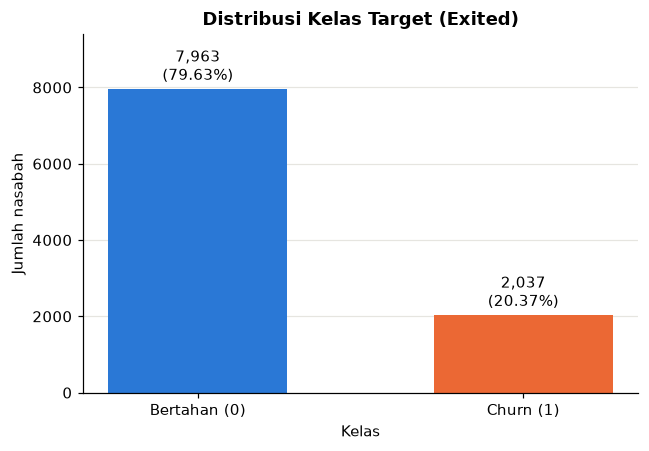

Bertahan (0): 7,963 nasabah (79.63%)
Churn    (1): 2,037 nasabah (20.37%)
Rasio kelas mayoritas : minoritas = 3.91 : 1
Akurasi model 'naif' yang selalu menebak kelas 0 = 79.63%
Dataset IMBALANCED: akurasi saja tidak cukup, perlu precision, recall, F1, dan AUC.


In [8]:
# Tampilkan distribusi kelas target (Exited) dalam bentuk bar plot.
# Perhatikan apakah dataset ini imbalanced.
jumlah = df["Exited"].value_counts().sort_index()
persen = df["Exited"].value_counts(normalize=True).sort_index() * 100

fig, ax = plt.subplots(figsize=(6, 4.2))
bars = ax.bar([LABEL_KELAS[k] for k in jumlah.index], jumlah.values,
              color=[WARNA_KELAS[k] for k in jumlah.index], width=0.55)
for b, n, p in zip(bars, jumlah.values, persen.values):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 100, f"{n:,}\n({p:.2f}%)",
            ha="center", va="bottom", fontsize=10)
ax.set_title("Distribusi Kelas Target (Exited)")
ax.set_xlabel("Kelas")
ax.set_ylabel("Jumlah nasabah")
ax.set_ylim(0, jumlah.max() * 1.18)
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

rasio = jumlah[0] / jumlah[1]
print(f"Bertahan (0): {jumlah[0]:,} nasabah ({persen[0]:.2f}%)")
print(f"Churn    (1): {jumlah[1]:,} nasabah ({persen[1]:.2f}%)")
print(f"Rasio kelas mayoritas : minoritas = {rasio:.2f} : 1")
print(f"Akurasi model 'naif' yang selalu menebak kelas 0 = {persen[0]:.2f}%")
print("Dataset IMBALANCED: akurasi saja tidak cukup, perlu precision, recall, F1, dan AUC.")

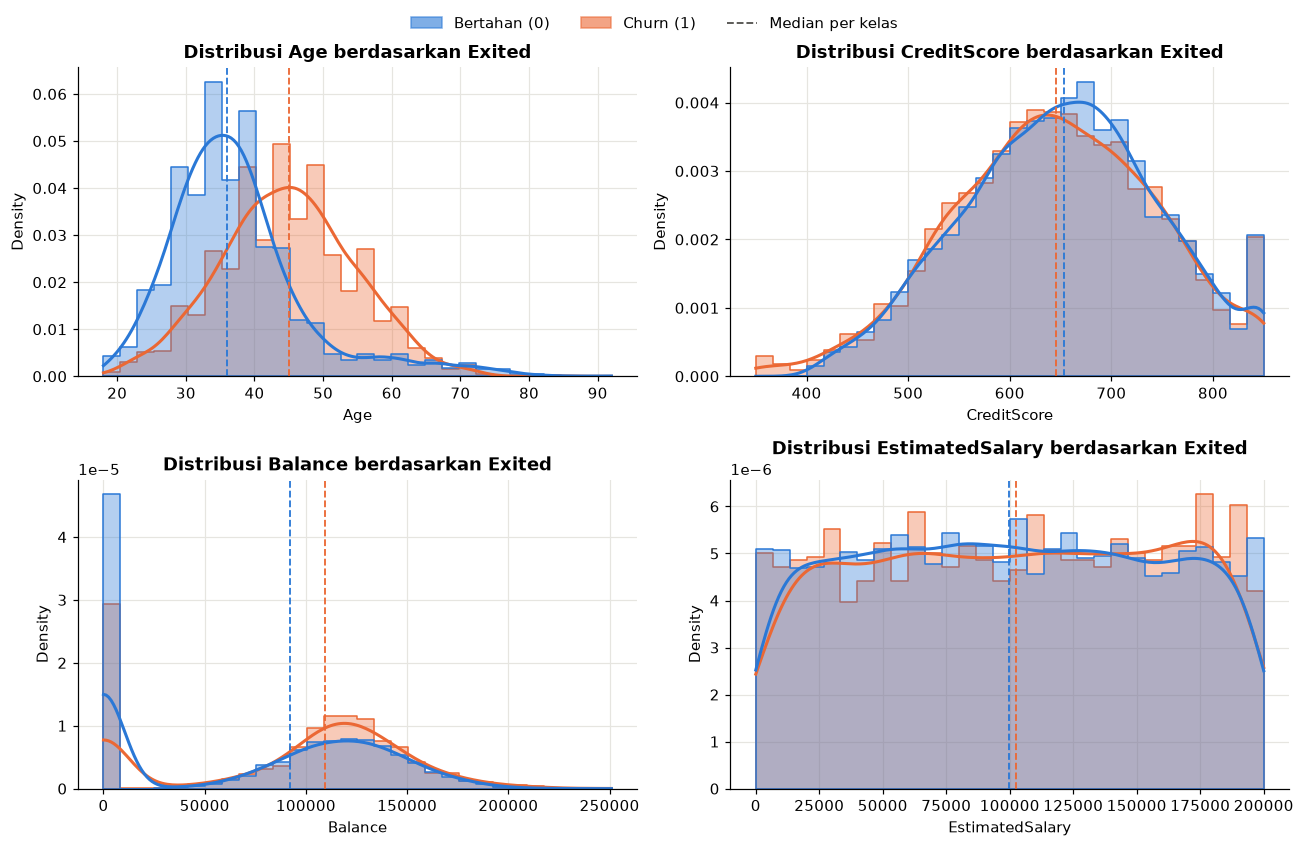

Rata-rata dan median fitur numerik per kelas Exited:


Exited                  Bertahan (0)    Churn (1)
Age             mean         37.4084      44.8380
                median       36.0000      45.0000
CreditScore     mean        651.8532     645.3515
                median      653.0000     646.0000
Balance         mean     72,745.2968  91,108.5393
                median   92,072.6800 109,349.2900
EstimatedSalary mean     99,738.3918 101,465.6775
                median   99,645.0400 102,460.8400

In [9]:
# Tampilkan distribusi fitur numerik (misalnya Age, CreditScore, Balance) menggunakan histogram atau KDE plot, dibedakan berdasarkan kelas Exited.
fitur_kontinu = ["Age", "CreditScore", "Balance", "EstimatedSalary"]

fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))
for ax, kolom in zip(axes.ravel(), fitur_kontinu):
    # stat="density" + common_norm=False: tiap kelas dinormalisasi sendiri,
    # sehingga bentuk distribusinya bisa dibandingkan walaupun jumlah datanya berbeda jauh.
    sns.histplot(data=df, x=kolom, hue="Exited", bins=30, stat="density", common_norm=False,
                 kde=True, palette=WARNA_KELAS, alpha=0.35, element="step",
                 line_kws={"linewidth": 2}, ax=ax, legend=False)
    for k in (0, 1):
        ax.axvline(df.loc[df["Exited"] == k, kolom].median(), color=WARNA_KELAS[k],
                   linestyle="--", linewidth=1.2)
    ax.set_title(f"Distribusi {kolom} berdasarkan Exited")
    ax.set_ylabel("Density")
handles = [plt.Rectangle((0, 0), 1, 1, color=WARNA_KELAS[k], alpha=0.6) for k in (0, 1)]
handles.append(plt.Line2D([0], [0], color="#52514e", linestyle="--", linewidth=1.2))
fig.legend(handles, [LABEL_KELAS[0], LABEL_KELAS[1], "Median per kelas"],
           loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.03))
plt.tight_layout()
plt.show()

print("Rata-rata dan median fitur numerik per kelas Exited:")
display(df.groupby("Exited")[fitur_kontinu].agg(["mean", "median"]).T.rename(columns=LABEL_KELAS))

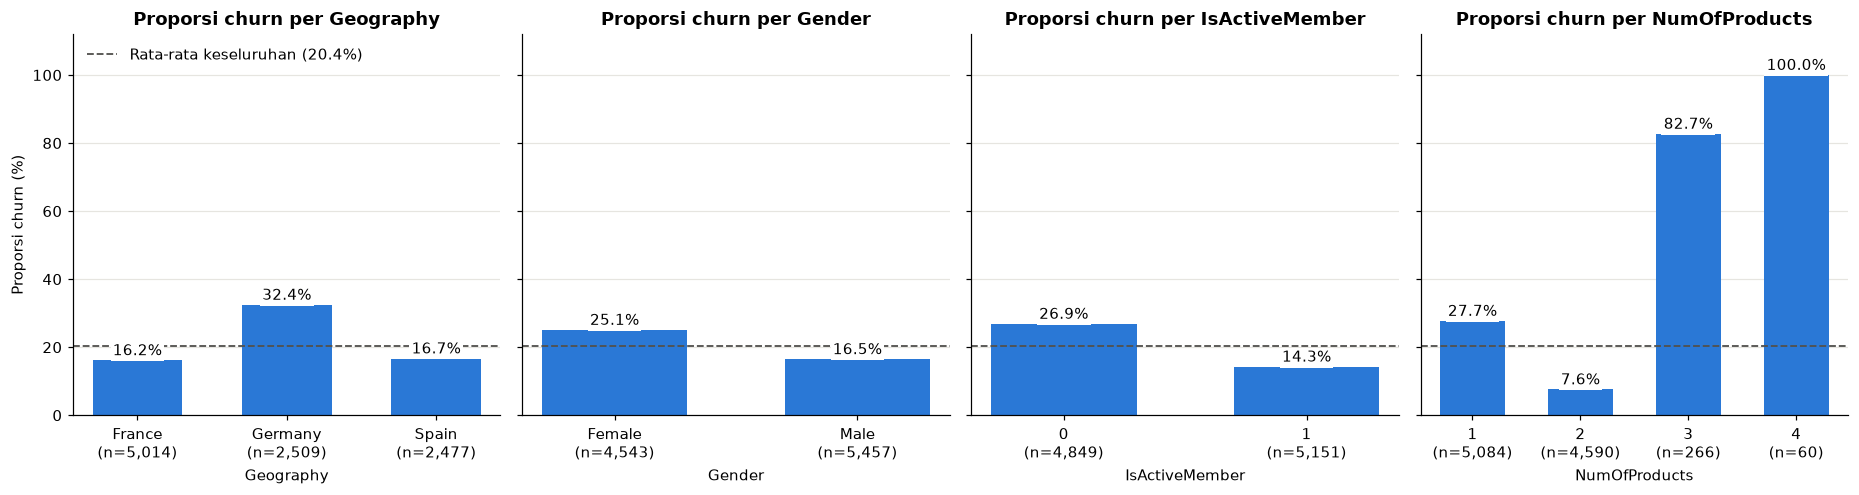


Proporsi churn (%) per Geography:


,jumlah_nasabah,jumlah_churn,proporsi_churn
Geography,,,
France,5014,810,16.1500
Germany,2509,814,32.4400
Spain,2477,413,16.6700



Proporsi churn (%) per Gender:


,jumlah_nasabah,jumlah_churn,proporsi_churn
Gender,,,
Female,4543,1139,25.0700
Male,5457,898,16.4600



Proporsi churn (%) per IsActiveMember:


,jumlah_nasabah,jumlah_churn,proporsi_churn
IsActiveMember,,,
0,4849,1302,26.8500
1,5151,735,14.2700



Proporsi churn (%) per NumOfProducts:


,jumlah_nasabah,jumlah_churn,proporsi_churn
NumOfProducts,,,
1,5084,1409,27.7100
2,4590,348,7.5800
3,266,220,82.7100
4,60,60,100.0000


In [10]:
# Tampilkan proporsi churn untuk setiap kategori pada fitur kategorikal (Geography, Gender, IsActiveMember, NumOfProducts).
fitur_kategorikal = ["Geography", "Gender", "IsActiveMember", "NumOfProducts"]
churn_total = df["Exited"].mean() * 100

fig, axes = plt.subplots(1, 4, figsize=(17, 4.6), sharey=True)
for ax, kolom in zip(axes, fitur_kategorikal):
    ringkas = df.groupby(kolom)["Exited"].agg(proporsi="mean", n="count")
    ringkas["proporsi"] *= 100
    label = [f"{idx}\n(n={n:,})" for idx, n in zip(ringkas.index, ringkas["n"])]
    bars = ax.bar(label, ringkas["proporsi"], color="#2a78d6", width=0.6)
    for b, v in zip(bars, ringkas["proporsi"]):
        ax.text(b.get_x() + b.get_width() / 2, v + 1.5, f"{v:.1f}%", ha="center", fontsize=10,
                bbox=dict(facecolor="white", edgecolor="none", pad=1.5))
    ax.axhline(churn_total, color="#52514e", linestyle="--", linewidth=1.2, zorder=1,
               label=f"Rata-rata keseluruhan ({churn_total:.1f}%)")
    ax.set_title(f"Proporsi churn per {kolom}")
    ax.set_xlabel(kolom)
    ax.set_ylim(0, 112)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Proporsi churn (%)")
axes[0].legend(loc="upper left")
plt.tight_layout()
plt.show()

for kolom in fitur_kategorikal:
    tabel = df.groupby(kolom)["Exited"].agg(jumlah_nasabah="count", jumlah_churn="sum", proporsi_churn="mean")
    tabel["proporsi_churn"] = (tabel["proporsi_churn"] * 100).round(2)
    print(f"\nProporsi churn (%) per {kolom}:")
    display(tabel)

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

### a. Korelasi antar fitur numerik dan target

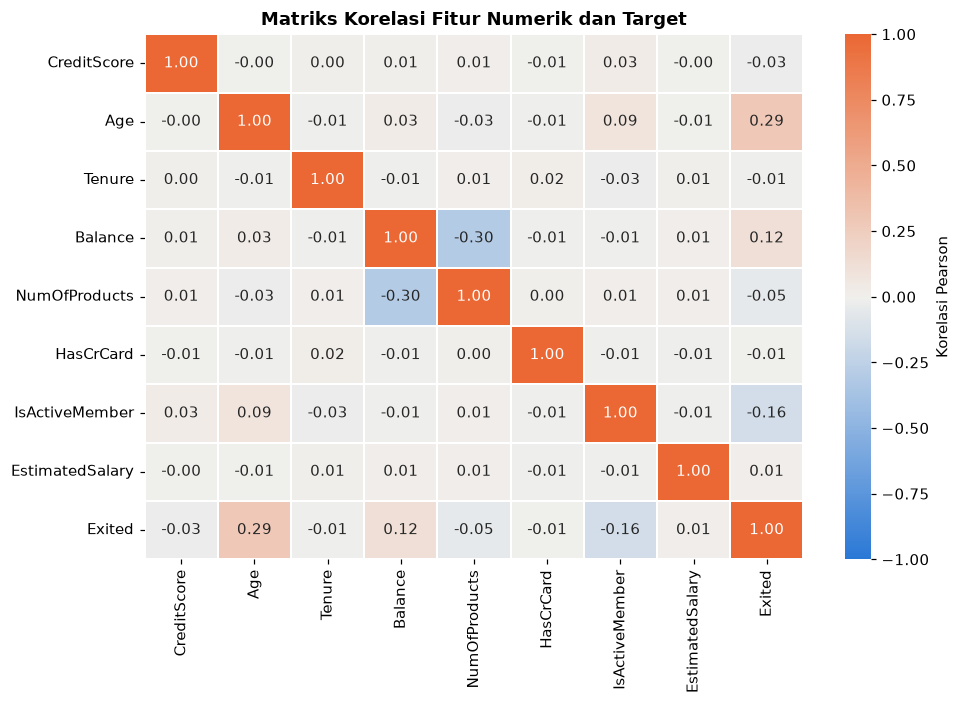

Korelasi setiap fitur terhadap Exited (diurutkan):


,korelasi_dengan_Exited
Age,0.2853
Balance,0.1185
EstimatedSalary,0.0121
HasCrCard,-0.0071
Tenure,-0.0140
CreditScore,-0.0271
NumOfProducts,-0.0478
IsActiveMember,-0.1561


In [11]:
# Korelasi Pearson antar fitur numerik dan target.
# Colormap diverging (biru = negatif, abu-abu netral = 0, oranye = positif).
kolom_numerik_semua = ["CreditScore", "Age", "Tenure", "Balance", "NumOfProducts",
                       "HasCrCard", "IsActiveMember", "EstimatedSalary", "Exited"]
korelasi = df[kolom_numerik_semua].corr()
cmap_div = LinearSegmentedColormap.from_list("biru_oranye", ["#2a78d6", "#f0efec", "#eb6834"])

fig, ax = plt.subplots(figsize=(9, 6.5))
sns.heatmap(korelasi, annot=True, fmt=".2f", cmap=cmap_div, vmin=-1, vmax=1, center=0,
            linewidths=1, linecolor="white", cbar_kws={"label": "Korelasi Pearson"}, ax=ax)
ax.set_title("Matriks Korelasi Fitur Numerik dan Target")
ax.grid(False)
plt.tight_layout()
plt.show()

print("Korelasi setiap fitur terhadap Exited (diurutkan):")
display(korelasi["Exited"].drop("Exited").sort_values(ascending=False).to_frame("korelasi_dengan_Exited"))

### b. Proporsi churn berdasarkan kelompok usia

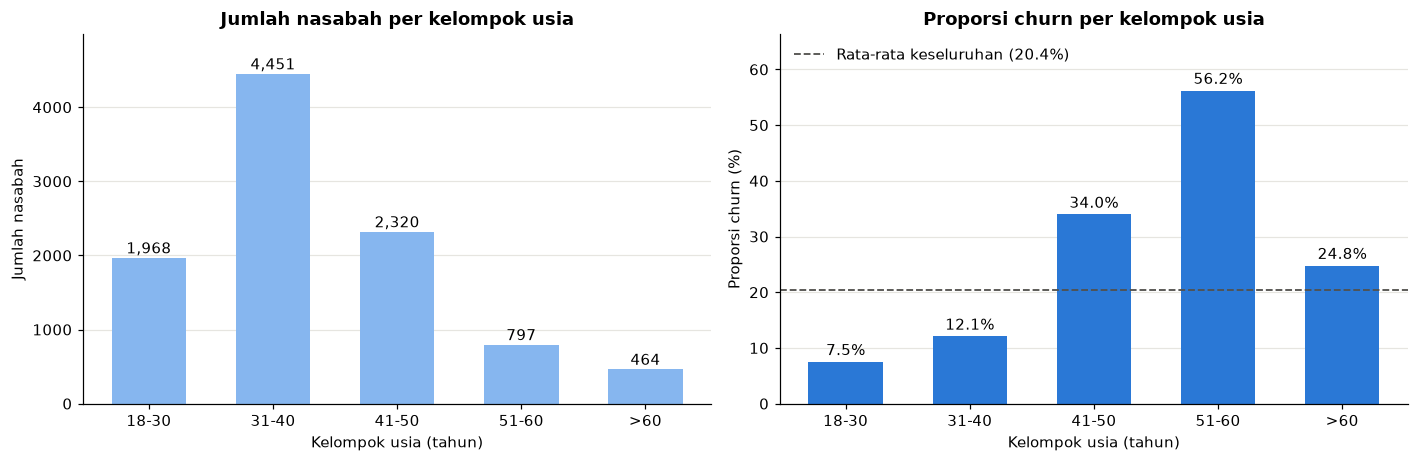

,jumlah_nasabah,proporsi_churn
Age,,
18-30,1968,7.5200
31-40,4451,12.0900
41-50,2320,33.9700
51-60,797,56.2100
>60,464,24.7800


In [12]:
# Usia adalah fitur dengan korelasi tertinggi terhadap churn, sehingga dilihat lebih detail per kelompok usia.
bins_usia = [17, 30, 40, 50, 60, 100]
label_usia = ["18-30", "31-40", "41-50", "51-60", ">60"]
kelompok_usia = pd.cut(df["Age"], bins=bins_usia, labels=label_usia)
ringkas_usia = df.groupby(kelompok_usia, observed=True)["Exited"].agg(jumlah_nasabah="count", proporsi_churn="mean")
ringkas_usia["proporsi_churn"] *= 100

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
b0 = axes[0].bar(ringkas_usia.index.astype(str), ringkas_usia["jumlah_nasabah"], color="#86b6ef", width=0.6)
for b, v in zip(b0, ringkas_usia["jumlah_nasabah"]):
    axes[0].text(b.get_x() + b.get_width() / 2, v + 60, f"{v:,}", ha="center", fontsize=10)
axes[0].set_title("Jumlah nasabah per kelompok usia")
axes[0].set_xlabel("Kelompok usia (tahun)"); axes[0].set_ylabel("Jumlah nasabah")
axes[0].set_ylim(0, ringkas_usia["jumlah_nasabah"].max() * 1.12)

b1 = axes[1].bar(ringkas_usia.index.astype(str), ringkas_usia["proporsi_churn"], color="#2a78d6", width=0.6)
for b, v in zip(b1, ringkas_usia["proporsi_churn"]):
    axes[1].text(b.get_x() + b.get_width() / 2, v + 1.2, f"{v:.1f}%", ha="center", fontsize=10)
axes[1].axhline(churn_total, color="#52514e", linestyle="--", linewidth=1.2, zorder=1,
                label=f"Rata-rata keseluruhan ({churn_total:.1f}%)")
axes[1].legend(loc="upper left")
axes[1].set_title("Proporsi churn per kelompok usia")
axes[1].set_xlabel("Kelompok usia (tahun)"); axes[1].set_ylabel("Proporsi churn (%)")
axes[1].set_ylim(0, ringkas_usia["proporsi_churn"].max() * 1.18)
for ax in axes:
    ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()
display(ringkas_usia.round(2))

### c. Saldo nol, Tenure, dan kepemilikan kartu kredit

Nasabah dengan saldo 0: 3,617 (36.17%)


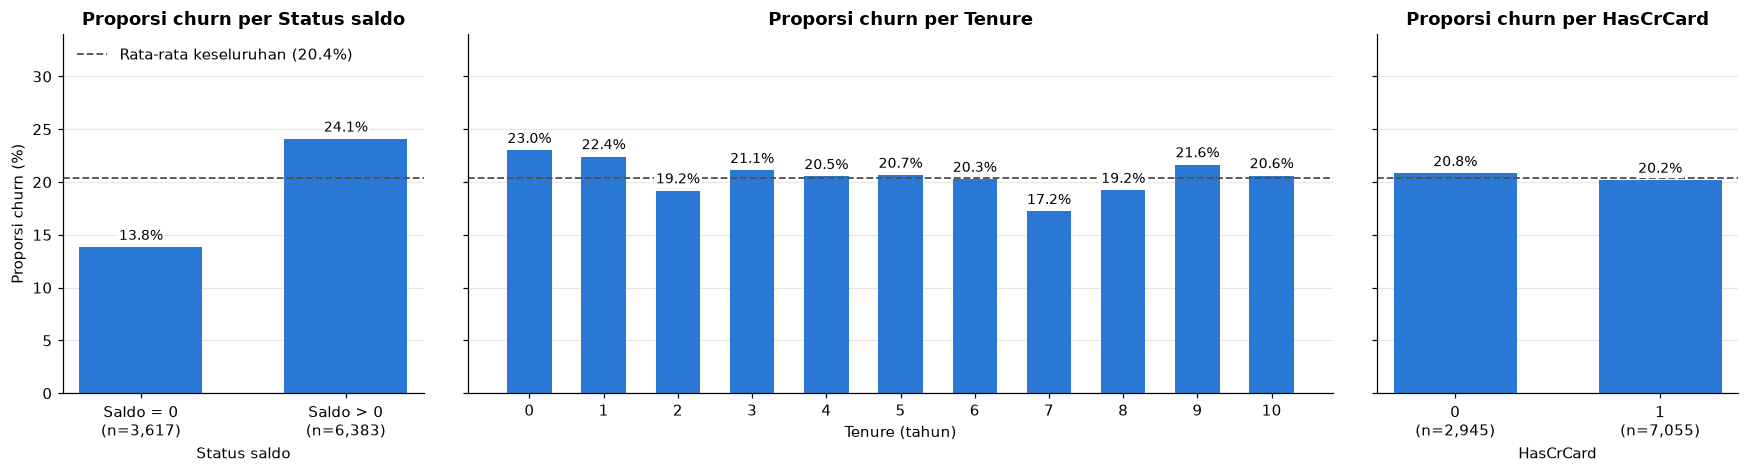

Proporsi nasabah bersaldo 0 dan proporsi churn per negara:


,jumlah_nasabah,persen_saldo_nol,rata_rata_saldo,proporsi_churn
Geography,,,,
France,5014,48.2200,"62,092.6400",16.1500
Germany,2509,0.0000,"119,730.1200",32.4400
Spain,2477,48.4100,"61,818.1500",16.6700


In [13]:
# Balance punya banyak nilai 0 (terlihat sebagai puncak di histogram), sehingga dicek terpisah.
df_eda = df.copy()
df_eda["Status saldo"] = np.where(df_eda["Balance"] == 0, "Saldo = 0", "Saldo > 0")
print(f"Nasabah dengan saldo 0: {(df['Balance'] == 0).sum():,} ({(df['Balance'] == 0).mean() * 100:.2f}%)")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4), sharey=True, gridspec_kw={"width_ratios": [1, 2.4, 1]})
for ax, kolom in zip(axes, ["Status saldo", "Tenure", "HasCrCard"]):
    ringkas = df_eda.groupby(kolom)["Exited"].agg(proporsi="mean", n="count")
    ringkas["proporsi"] *= 100
    if kolom == "Tenure":
        label = [str(i) for i in ringkas.index]
    else:
        label = [f"{idx}\n(n={n:,})" for idx, n in zip(ringkas.index, ringkas["n"])]
    bars = ax.bar(label, ringkas["proporsi"], color="#2a78d6", width=0.6)
    for b, v in zip(bars, ringkas["proporsi"]):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.7, f"{v:.1f}%", ha="center", fontsize=9,
                bbox=dict(facecolor="white", edgecolor="none", pad=1.5))
    ax.axhline(churn_total, color="#52514e", linestyle="--", linewidth=1.2, zorder=1,
               label=f"Rata-rata keseluruhan ({churn_total:.1f}%)")
    ax.set_title(f"Proporsi churn per {kolom}")
    ax.set_xlabel(kolom + (" (tahun)" if kolom == "Tenure" else ""))
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Proporsi churn (%)")
axes[0].set_ylim(0, 34)
axes[0].legend(loc="upper left")
plt.tight_layout()
plt.show()

print("Proporsi nasabah bersaldo 0 dan proporsi churn per negara:")
display(df_eda.groupby("Geography").agg(
    jumlah_nasabah=("Exited", "count"),
    persen_saldo_nol=("Balance", lambda s: (s == 0).mean() * 100),
    rata_rata_saldo=("Balance", "mean"),
    proporsi_churn=("Exited", lambda s: s.mean() * 100)).round(2))

### d. Interaksi antar fitur kategorikal

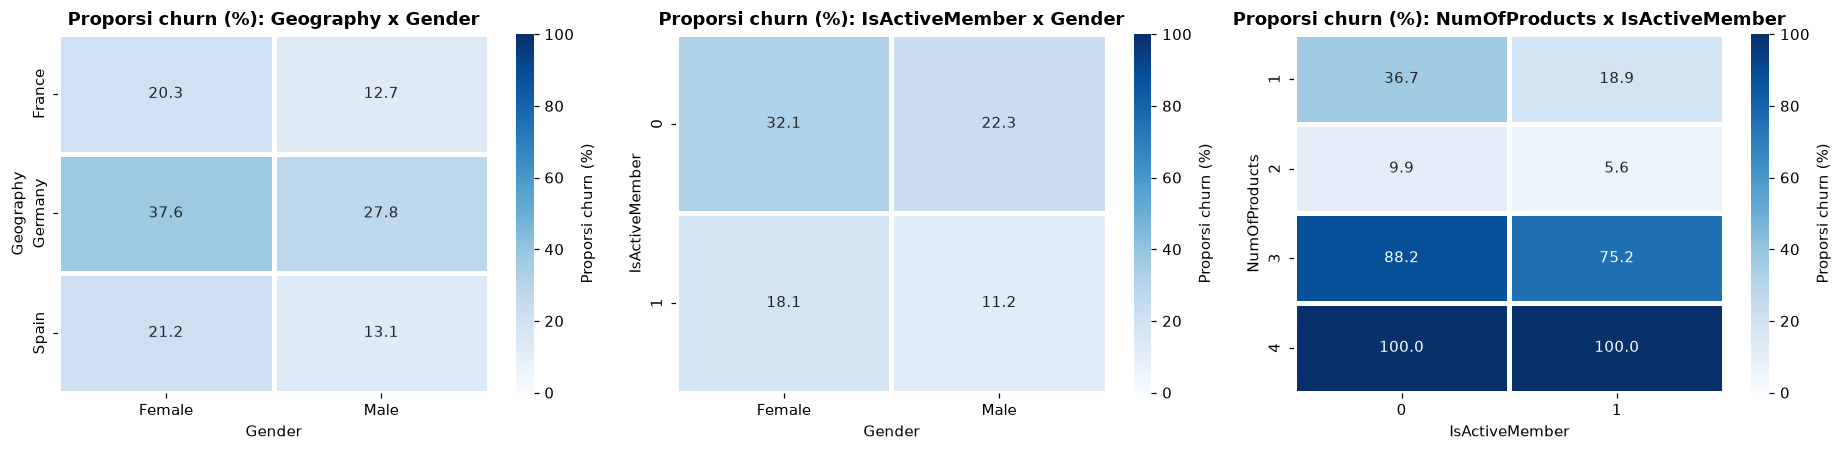

Jumlah nasabah per NumOfProducts x IsActiveMember (untuk menilai seberapa besar tiap sel):


IsActiveMember,0,1
NumOfProducts,,
1,2521,2563
2,2144,2446
3,153,113
4,31,29


In [14]:
# Proporsi churn (%) untuk kombinasi dua fitur kategorikal. Colormap sekuensial satu warna (terang -> gelap).
kombinasi = [("Geography", "Gender"), ("IsActiveMember", "Gender"), ("NumOfProducts", "IsActiveMember")]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for ax, (baris, kolom) in zip(axes, kombinasi):
    pivot = df.pivot_table(index=baris, columns=kolom, values="Exited", aggfunc="mean") * 100
    sns.heatmap(pivot, annot=True, fmt=".1f", cmap="Blues", vmin=0, vmax=100, linewidths=2,
                linecolor="white", cbar_kws={"label": "Proporsi churn (%)"}, ax=ax)
    ax.set_title(f"Proporsi churn (%): {baris} x {kolom}")
    ax.grid(False)
plt.tight_layout()
plt.show()

print("Jumlah nasabah per NumOfProducts x IsActiveMember (untuk menilai seberapa besar tiap sel):")
display(pd.crosstab(df["NumOfProducts"], df["IsActiveMember"]))

### e. Pemeriksaan outlier dan skala fitur

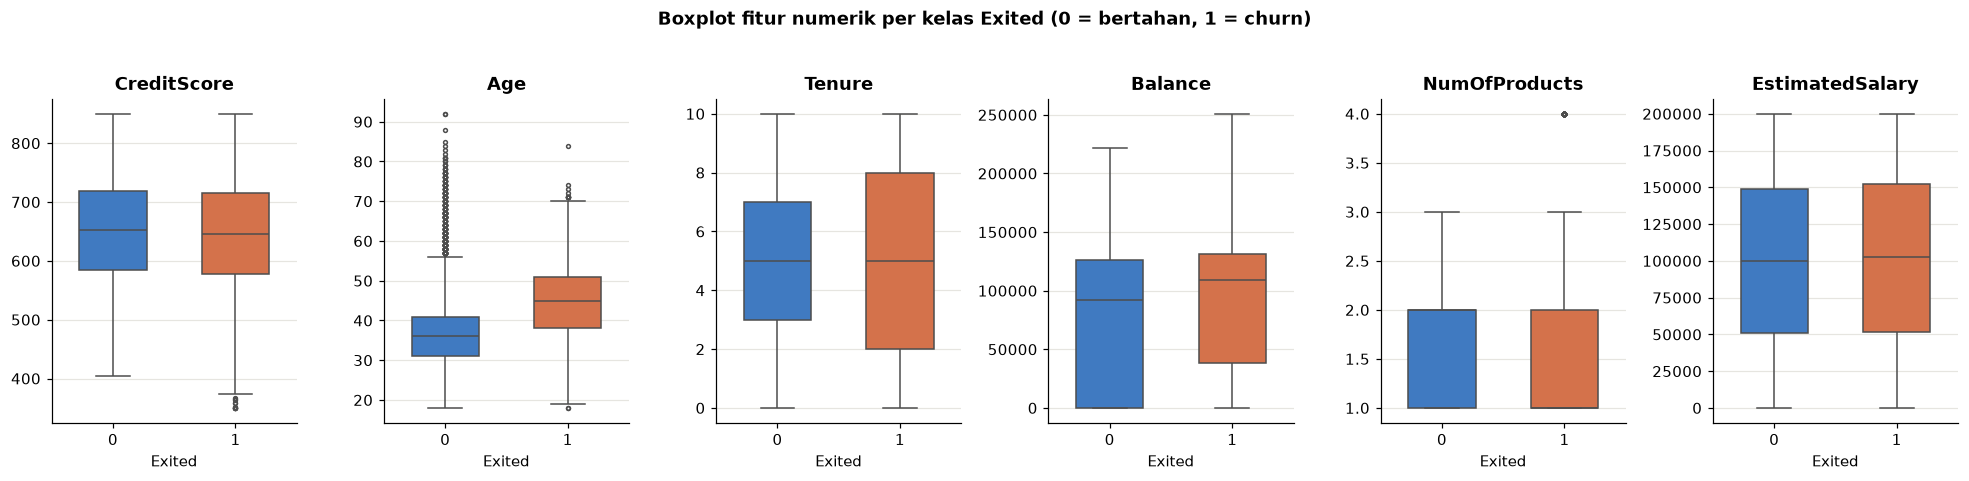

Rentang nilai dan jumlah outlier (aturan 1.5 x IQR):


,min,max,mean,std,jumlah_outlier_IQR,persen_outlier
fitur,,,,,,
CreditScore,350.0000,850.0000,650.5300,96.6500,15,0.1500
Age,18.0000,92.0000,38.9200,10.4900,359,3.5900
Tenure,0.0000,10.0000,5.0100,2.8900,0,0.0000
Balance,0.0000,"250,898.0900","76,485.8900","62,397.4100",0,0.0000
NumOfProducts,1.0000,4.0000,1.5300,0.5800,60,0.6000
EstimatedSalary,11.5800,"199,992.4800","100,090.2400","57,510.4900",0,0.0000


In [15]:
# Boxplot per kelas untuk melihat sebaran dan outlier, lalu jumlah outlier dengan aturan 1.5 x IQR.
fitur_box = ["CreditScore", "Age", "Tenure", "Balance", "NumOfProducts", "EstimatedSalary"]
fig, axes = plt.subplots(1, 6, figsize=(18, 4.2))
for ax, kolom in zip(axes, fitur_box):
    sns.boxplot(data=df, x="Exited", y=kolom, hue="Exited", palette=WARNA_KELAS, width=0.55,
                linewidth=1, fliersize=2.5, legend=False, ax=ax)
    ax.set_title(kolom)
    ax.set_xlabel("Exited"); ax.set_ylabel("")
    ax.grid(axis="x", visible=False)
fig.suptitle("Boxplot fitur numerik per kelas Exited (0 = bertahan, 1 = churn)", fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

baris_outlier = []
for kolom in fitur_box:
    q1, q3 = df[kolom].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = int(((df[kolom] < q1 - 1.5 * iqr) | (df[kolom] > q3 + 1.5 * iqr)).sum())
    baris_outlier.append({"fitur": kolom, "min": df[kolom].min(), "max": df[kolom].max(),
                          "mean": df[kolom].mean(), "std": df[kolom].std(),
                          "jumlah_outlier_IQR": n_out, "persen_outlier": n_out / len(df) * 100})
print("Rentang nilai dan jumlah outlier (aturan 1.5 x IQR):")
display(pd.DataFrame(baris_outlier).set_index("fitur").round(2))

# 2. Preprocessing

ANN hanya menerima input numerik dan sangat sensitif terhadap skala fitur. Perhatikan jenis setiap kolom sebelum memilih preprocessing:

| Jenis kolom | Contoh | Preprocessing |
|---|---|---|
| Identitas (tidak informatif) | RowNumber, CustomerId, Surname | Drop |
| Kategorikal nominal | Geography | OneHotEncoder |
| Kategorikal biner | Gender | Encode menjadi 0/1 |
| Numerik | CreditScore, Age, Balance, dll. | StandardScaler |

In [16]:
# Drop kolom yang tidak relevan untuk prediksi.
# Jelaskan secara singkat (dalam komentar) alasan kolom tersebut di-drop.

# Alasan kolom di-drop:
# - RowNumber  : hanya nomor urut baris, tidak membawa informasi apa pun tentang perilaku nasabah.
# - CustomerId : ID unik tiap nasabah (10.000 nilai unik), tidak punya pola yang bisa digeneralisasi.
#                Jika dipakai, model justru berisiko "menghafal" ID (overfitting).
# - Surname    : nama keluarga dengan kardinalitas sangat tinggi (ribuan nilai unik). Tidak berhubungan
#                secara kausal dengan churn, dan one-hot encoding-nya akan menghasilkan ribuan kolom sparse.
kolom_drop = ["RowNumber", "CustomerId", "Surname"]
df_model = df.drop(columns=kolom_drop)

print("Kolom yang di-drop :", kolom_drop)
print("Ukuran data        :", df.shape, "->", df_model.shape)
print("Kolom tersisa      :", df_model.columns.tolist())
display(df_model.head())

Kolom yang di-drop : ['RowNumber', 'CustomerId', 'Surname']
Ukuran data        : (10000, 14) -> (10000, 11)
Kolom tersisa      : ['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']


,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.0000,1,1,1,"101,348.8800",1
1,608,Spain,Female,41,1,"83,807.8600",1,0,1,"112,542.5800",0
2,502,France,Female,42,8,"159,660.8000",3,1,0,"113,931.5700",1
3,699,France,Female,39,1,0.0000,2,0,0,"93,826.6300",0
4,850,Spain,Female,43,2,"125,510.8200",1,1,1,"79,084.1000",0


In [18]:
# Pisahkan fitur (X) dan target (y).
# Bagi data menjadi train set, validation set, dan test set (misalnya 70:15:15).
# Gunakan stratify=y agar distribusi kelas tetap proporsional di setiap set.
# Validation set digunakan untuk memantau training (learning curve), test set hanya digunakan untuk evaluasi akhir.
X = df_model.drop(columns="Exited")
y = df_model["Exited"]

# Tahap 1: 70% train, 30% sementara. Tahap 2: 30% sementara dibagi dua -> 15% validation, 15% test.
X_train_raw, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SEED)
X_val_raw, X_test_raw, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED)

ringkas_split = pd.DataFrame({
    "jumlah_data": [len(y_train), len(y_val), len(y_test)],
    "persen_dari_total": [len(y_train) / len(y) * 100, len(y_val) / len(y) * 100, len(y_test) / len(y) * 100],
    "jumlah_churn": [int(y_train.sum()), int(y_val.sum()), int(y_test.sum())],
    "proporsi_churn_%": [y_train.mean() * 100, y_val.mean() * 100, y_test.mean() * 100],
}, index=["Train", "Validation", "Test"])
print("Hasil pembagian data (stratified):")
display(ringkas_split.round(2))
print(f"Proporsi churn data keseluruhan: {y.mean() * 100:.2f}% -> proporsi kelas terjaga di ketiga set.")

Hasil pembagian data (stratified):


,jumlah_data,persen_dari_total,jumlah_churn,proporsi_churn_%
Train,7000,70.0000,1426,20.3700
Validation,1500,15.0000,306,20.4000
Test,1500,15.0000,305,20.3300


Proporsi churn data keseluruhan: 20.37% -> proporsi kelas terjaga di ketiga set.


In [19]:
# Lakukan encoding pada fitur kategorikal dan scaling pada fitur numerik.
# Fit encoder dan scaler hanya pada train set, kemudian transform pada train, validation, dan test set.
# Disarankan menggunakan ColumnTransformer agar rapi.
kolom_numerik = ["CreditScore", "Age", "Tenure", "Balance", "NumOfProducts", "EstimatedSalary"]
kolom_nominal = ["Geography"]                    # 3 kategori tanpa urutan -> OneHotEncoder
kolom_biner = ["Gender"]                         # 2 kategori -> 0/1 (Female = 0, Male = 1)
kolom_sudah_biner = ["HasCrCard", "IsActiveMember"]   # sudah 0/1 -> diteruskan apa adanya

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), kolom_numerik),
        ("geo", OneHotEncoder(handle_unknown="ignore", sparse_output=False), kolom_nominal),
        ("gender", OrdinalEncoder(categories=[["Female", "Male"]]), kolom_biner),
        ("biner", "passthrough", kolom_sudah_biner),
    ],
    verbose_feature_names_out=False,
)

# Fit HANYA pada train set agar tidak ada kebocoran informasi (data leakage) dari validation/test,
# kemudian transform ke ketiga set dengan parameter (mean, std, kategori) milik train set.
X_train = preprocessor.fit_transform(X_train_raw)
X_val = preprocessor.transform(X_val_raw)
X_test = preprocessor.transform(X_test_raw)

nama_fitur = preprocessor.get_feature_names_out().tolist()
print("Jumlah fitur setelah preprocessing:", len(nama_fitur))
print("Nama fitur:", nama_fitur)

print("\nContoh 5 baris train set setelah preprocessing:")
display(pd.DataFrame(X_train, columns=nama_fitur).head())

print("Mean dan std fitur numerik (train harus ~0 dan ~1; validation/test mendekati, tidak persis):")
cek = pd.DataFrame({
    "train_mean": X_train[:, :len(kolom_numerik)].mean(axis=0),
    "train_std": X_train[:, :len(kolom_numerik)].std(axis=0),
    "val_mean": X_val[:, :len(kolom_numerik)].mean(axis=0),
    "val_std": X_val[:, :len(kolom_numerik)].std(axis=0),
    "test_mean": X_test[:, :len(kolom_numerik)].mean(axis=0),
    "test_std": X_test[:, :len(kolom_numerik)].std(axis=0),
}, index=kolom_numerik)
display(cek.round(3))

Jumlah fitur setelah preprocessing: 12
Nama fitur: ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'EstimatedSalary', 'Geography_France', 'Geography_Germany', 'Geography_Spain', 'Gender', 'HasCrCard', 'IsActiveMember']

Contoh 5 baris train set setelah preprocessing:


,CreditScore,Age,Tenure,Balance,NumOfProducts,EstimatedSalary,Geography_France,Geography_Germany,Geography_Spain,Gender,HasCrCard,IsActiveMember
0,-0.5756,-1.7967,-0.3495,0.3129,-0.9125,1.3625,1.0000,0.0000,0.0000,1.0000,1.0000,0.0000
1,0.3982,2.2698,-1.3869,-1.2236,0.7995,1.5155,0.0000,0.0000,1.0000,0.0000,1.0000,1.0000
2,1.6931,-0.7564,-1.3869,0.6823,-0.9125,0.0390,1.0000,0.0000,0.0000,1.0000,1.0000,0.0000
3,0.7400,-1.7967,0.3422,-1.2236,0.7995,1.6714,1.0000,0.0000,0.0000,1.0000,1.0000,0.0000
4,0.9058,-1.9858,-0.3495,-1.2236,0.7995,-0.8994,1.0000,0.0000,0.0000,1.0000,1.0000,1.0000


Mean dan std fitur numerik (train harus ~0 dan ~1; validation/test mendekati, tidak persis):


,train_mean,train_std,val_mean,val_std,test_mean,test_std
CreditScore,0.0000,1.0000,-0.0020,1.0070,-0.0000,1.0010
Age,0.0000,1.0000,-0.0230,0.9690,-0.0250,0.9750
Tenure,-0.0000,1.0000,0.0510,0.9770,-0.0460,1.0210
Balance,-0.0000,1.0000,-0.0040,1.0030,0.0220,0.9990
NumOfProducts,-0.0000,1.0000,-0.0200,0.9770,-0.0120,0.9940
EstimatedSalary,0.0000,1.0000,0.0430,1.0000,0.0290,1.0060


In [20]:
# Pastikan X dan y untuk train, validation, dan test berupa numpy array bertipe float32.
# Contoh: X_train = np.asarray(X_train, dtype="float32")
X_train = np.asarray(X_train, dtype="float32")
X_val = np.asarray(X_val, dtype="float32")
X_test = np.asarray(X_test, dtype="float32")

y_train = np.asarray(y_train, dtype="float32")
y_val = np.asarray(y_val, dtype="float32")
y_test = np.asarray(y_test, dtype="float32")

for nama, arr in [("X_train", X_train), ("X_val", X_val), ("X_test", X_test),
                  ("y_train", y_train), ("y_val", y_val), ("y_test", y_test)]:
    print(f"{nama:8s} | tipe: {type(arr).__name__} | dtype: {arr.dtype} | shape: {arr.shape} | NaN: {int(np.isnan(arr).sum())}")

n_features = X_train.shape[1]
print("\nJumlah fitur input ANN:", n_features)

# Wadah untuk menyimpan hasil prediksi semua model (dipakai pada bagian 4. Evaluasi)
hasil = {}       # nama model -> {"y_pred": label, "y_prob": probabilitas kelas 1} pada TEST set
histories = {}   # nama model ANN -> objek History

X_train  | tipe: ndarray | dtype: float32 | shape: (7000, 12) | NaN: 0
X_val    | tipe: ndarray | dtype: float32 | shape: (1500, 12) | NaN: 0
X_test   | tipe: ndarray | dtype: float32 | shape: (1500, 12) | NaN: 0
y_train  | tipe: ndarray | dtype: float32 | shape: (7000,) | NaN: 0
y_val    | tipe: ndarray | dtype: float32 | shape: (1500,) | NaN: 0
y_test   | tipe: ndarray | dtype: float32 | shape: (1500,) | NaN: 0

Jumlah fitur input ANN: 12


# 3. Eksperimen Model

## 3.1 Baseline: Logistic Regression

Sebelum membangun ANN, buat model sederhana sebagai pembanding. Model yang lebih kompleks hanya layak digunakan jika performanya lebih baik dari baseline.

In [21]:
# Inisialisasi dan latih model Logistic Regression (sklearn) menggunakan train set.
# Lakukan prediksi pada test set, simpan hasil prediksi label dan probabilitas kelas 1.
logreg = LogisticRegression(max_iter=1000, random_state=SEED)
logreg.fit(X_train, y_train)

y_pred_lr = logreg.predict(X_test).astype(int)          # label prediksi
y_prob_lr = logreg.predict_proba(X_test)[:, 1]          # probabilitas kelas 1 (churn)
hasil["Logistic Regression"] = {"y_pred": y_pred_lr, "y_prob": y_prob_lr}

print("Logistic Regression selesai dilatih.")
print(f"Akurasi train      : {logreg.score(X_train, y_train):.4f}")
print(f"Akurasi validation : {logreg.score(X_val, y_val):.4f}")
print(f"Akurasi test       : {accuracy_score(y_test, y_pred_lr):.4f}")
print(f"Jumlah prediksi churn pada test set: {int(y_pred_lr.sum())} dari {len(y_pred_lr)} (aktual churn: {int(y_test.sum())})")

print("\nKoefisien Logistic Regression (fitur numerik sudah distandardisasi sehingga besarnya dapat dibandingkan):")
display(pd.DataFrame({"fitur": nama_fitur, "koefisien": logreg.coef_[0]})
        .sort_values("koefisien", key=np.abs, ascending=False).set_index("fitur"))

Logistic Regression selesai dilatih.
Akurasi train      : 0.8119
Akurasi validation : 0.8100
Akurasi test       : 0.8153
Jumlah prediksi churn pada test set: 96 dari 1500 (aktual churn: 305)

Koefisien Logistic Regression (fitur numerik sudah distandardisasi sehingga besarnya dapat dibandingkan):


,koefisien
fitur,
IsActiveMember,-1.0081
Age,0.7047
Gender,-0.4957
Geography_France,-0.4614
Geography_Spain,-0.4374
Geography_Germany,0.3494
Balance,0.1521
CreditScore,-0.1008
EstimatedSalary,0.0505


## 3.2 ANN Sederhana

Bangun ANN dengan **1 hidden layer**. Karena ini klasifikasi biner, gunakan **1 neuron output dengan aktivasi Sigmoid** dan **Binary Cross-Entropy** sebagai loss function.

Contoh arsitektur: `Input → Dense(16, ReLU) → Dense(1, Sigmoid)`

In [22]:
# Definisikan arsitektur ANN sederhana menggunakan keras.Sequential.
# Gunakan keras.Input(shape=(jumlah_fitur,)) sebagai layer pertama, lalu layers.Dense untuk hidden layer dan output layer.
# Tampilkan ringkasan model beserta jumlah parameternya dengan model.summary().
def build_ann_sederhana(n_features):
    """ANN dengan 1 hidden layer: Input -> Dense(16, ReLU) -> Dense(1, Sigmoid)."""
    return keras.Sequential([
        keras.Input(shape=(n_features,)),
        layers.Dense(16, activation="relu", name="hidden_1"),
        layers.Dense(1, activation="sigmoid", name="output"),
    ], name="ANN_Sederhana")

tf.keras.utils.set_random_seed(SEED)   # inisialisasi bobot yang sama setiap kali sel dijalankan
model_sederhana = build_ann_sederhana(n_features)
model_sederhana.summary()

# Perhitungan manual jumlah parameter: (input x neuron + bias) tiap layer
print(f"hidden_1 : {n_features} x 16 + 16 = {n_features * 16 + 16}")
print(f"output   : 16 x 1 + 1 = {16 + 1}")
print(f"Total    : {model_sederhana.count_params()} parameter")

Model: "ANN_Sederhana"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_1 (Dense)                │ (None, 16)             │           208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225 (900.00 B)

 Trainable params: 225 (900.00 B)

 Non-trainable params: 0 (0.00 B)

hidden_1 : 12 x 16 + 16 = 208
output   : 16 x 1 + 1 = 17
Total    : 225 parameter


In [23]:
# Compile model: tentukan optimizer (misalnya keras.optimizers.Adam(learning_rate=...)), loss="binary_crossentropy", dan metrics=["accuracy"].
# Latih model dengan model.fit(), gunakan validation_data=(X_val, y_val) agar loss dan accuracy validation tercatat setiap epoch.
# Simpan hasil model.fit() ke variabel history.

# Hyperparameter training (dipakai sama untuk semua ANN agar perbandingannya adil)
LEARNING_RATE = 0.001
EPOCHS = 100
BATCH_SIZE = 32

model_sederhana.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

history = model_sederhana.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=0,
)
histories["ANN Sederhana"] = history

def tampilkan_log(history, tiap=10):
    """Tampilkan loss dan accuracy train/validation setiap `tiap` epoch."""
    log = pd.DataFrame(history.history)
    log.index = log.index + 1
    log.index.name = "epoch"
    display(log.loc[[1] + list(range(tiap, len(log) + 1, tiap))].round(4))

print(f"Training selesai: {EPOCHS} epoch, batch size {BATCH_SIZE}, Adam (lr={LEARNING_RATE}).")
tampilkan_log(history)

Training selesai: 100 epoch, batch size 32, Adam (lr=0.001).


,accuracy,loss,val_accuracy,val_loss
epoch,,,,
1,0.6817,0.6025,0.7960,0.4805
10,0.8533,0.3567,0.8587,0.3421
20,0.8566,0.3464,0.8600,0.3328
30,0.8573,0.3423,0.8647,0.3293
40,0.8581,0.3401,0.8660,0.3278
50,0.8591,0.3382,0.8667,0.3261
60,0.8609,0.3362,0.8693,0.3242
70,0.8613,0.3350,0.8713,0.3231
80,0.8611,0.3342,0.8693,0.3225


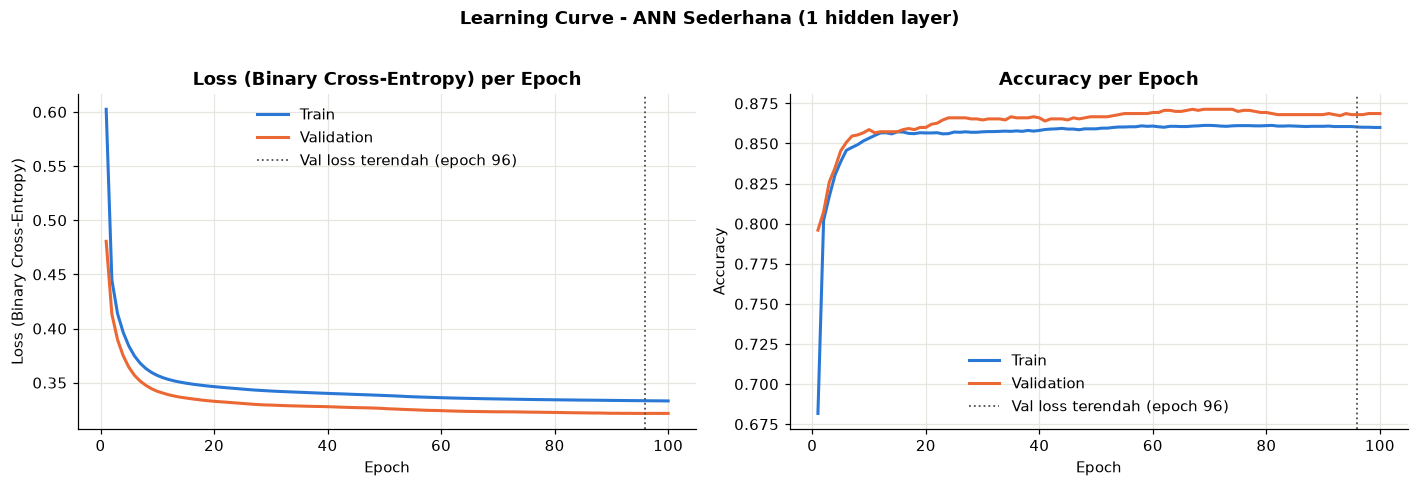

[ANN Sederhana (1 hidden layer)]
  Epoch terakhir (100): train loss = 0.3332 | val loss = 0.3217 | selisih (val - train) = -0.0115
                       train acc  = 0.8600 | val acc  = 0.8687
  Val loss terendah = 0.3216 pada epoch 96; kenaikan val loss sesudahnya = +0.0000


In [24]:
# Tampilkan learning curve (loss dan accuracy) train vs validation dalam bentuk line plot.
# Gunakan history.history["loss"], history.history["val_loss"], history.history["accuracy"], dan history.history["val_accuracy"].
def plot_learning_curve(history, judul):
    """Line plot loss dan accuracy (train vs validation) per epoch."""
    h = history.history
    epoch = np.arange(1, len(h["loss"]) + 1)
    epoch_terbaik = int(np.argmin(h["val_loss"])) + 1

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
    for ax, metrik, nama in zip(axes, ["loss", "accuracy"], ["Loss (Binary Cross-Entropy)", "Accuracy"]):
        ax.plot(epoch, h[metrik], color=WARNA_TRAIN, linewidth=2, label="Train")
        ax.plot(epoch, h["val_" + metrik], color=WARNA_VAL, linewidth=2, label="Validation")
        ax.axvline(epoch_terbaik, color="#52514e", linestyle=":", linewidth=1.2,
                   label=f"Val loss terendah (epoch {epoch_terbaik})")
        ax.set_title(f"{nama} per Epoch")
        ax.set_xlabel("Epoch"); ax.set_ylabel(nama)
        ax.legend()
    fig.suptitle(f"Learning Curve - {judul}", fontweight="bold", y=1.02)
    plt.tight_layout()
    plt.show()

    print(f"[{judul}]")
    print(f"  Epoch terakhir ({len(epoch)}): train loss = {h['loss'][-1]:.4f} | val loss = {h['val_loss'][-1]:.4f} "
          f"| selisih (val - train) = {h['val_loss'][-1] - h['loss'][-1]:+.4f}")
    print(f"                       train acc  = {h['accuracy'][-1]:.4f} | val acc  = {h['val_accuracy'][-1]:.4f}")
    print(f"  Val loss terendah = {min(h['val_loss']):.4f} pada epoch {epoch_terbaik}; "
          f"kenaikan val loss sesudahnya = {h['val_loss'][-1] - min(h['val_loss']):+.4f}")

plot_learning_curve(history, "ANN Sederhana (1 hidden layer)")

In [25]:
# Lakukan prediksi pada test set dengan model.predict(X_test). Hasilnya berupa probabilitas kelas 1.
# Ubah menjadi label dengan threshold 0.5, lalu simpan probabilitas dan label untuk keperluan evaluasi.
y_prob_sederhana = model_sederhana.predict(X_test, verbose=0).ravel()   # probabilitas kelas 1
y_pred_sederhana = (y_prob_sederhana >= 0.5).astype(int)                # label dengan threshold 0.5
hasil["ANN Sederhana"] = {"y_pred": y_pred_sederhana, "y_prob": y_prob_sederhana}

print("Contoh 10 probabilitas pertama:", np.round(y_prob_sederhana[:10], 3))
print("Label hasil threshold 0.5    :", y_pred_sederhana[:10])
print("Label aktual                 :", y_test[:10].astype(int))
print(f"\nAkurasi test: {accuracy_score(y_test, y_pred_sederhana):.4f}")
print(f"Jumlah prediksi churn pada test set: {int(y_pred_sederhana.sum())} dari {len(y_pred_sederhana)} (aktual churn: {int(y_test.sum())})")

Contoh 10 probabilitas pertama: [0.188 0.009 0.053 0.052 0.239 0.02  0.014 0.138 0.363 0.802]
Label hasil threshold 0.5    : [0 0 0 0 0 0 0 0 0 1]
Label aktual                 : [0 0 0 0 0 0 0 0 1 1]

Akurasi test: 0.8693
Jumlah prediksi churn pada test set: 189 dari 1500 (aktual churn: 305)


## 3.3 ANN Lebih Dalam dengan Dropout

Bangun ANN dengan **2–3 hidden layer** dan tambahkan **Dropout** di antara hidden layer untuk mengurangi overfitting.

In [26]:
# Definisikan arsitektur ANN yang lebih dalam, tambahkan layers.Dropout(rate) di antara hidden layer.
# Tampilkan ringkasan model beserta jumlah parameternya.
DROPOUT_RATE = 0.3

def build_ann_dalam(n_features, dropout_rate=DROPOUT_RATE):
    """ANN dengan 3 hidden layer (64 -> 32 -> 16) dan Dropout di antara hidden layer."""
    return keras.Sequential([
        keras.Input(shape=(n_features,)),
        layers.Dense(64, activation="relu", name="hidden_1"),
        layers.Dropout(dropout_rate, name="dropout_1"),
        layers.Dense(32, activation="relu", name="hidden_2"),
        layers.Dropout(dropout_rate, name="dropout_2"),
        layers.Dense(16, activation="relu", name="hidden_3"),
        layers.Dense(1, activation="sigmoid", name="output"),
    ], name="ANN_Dalam_Dropout")

tf.keras.utils.set_random_seed(SEED)
model_dalam = build_ann_dalam(n_features)
model_dalam.summary()

print(f"hidden_1 : {n_features} x 64 + 64 = {n_features * 64 + 64}")
print(f"hidden_2 : 64 x 32 + 32 = {64 * 32 + 32}")
print(f"hidden_3 : 32 x 16 + 16 = {32 * 16 + 16}")
print(f"output   : 16 x 1 + 1 = {16 + 1}")
print(f"Total    : {model_dalam.count_params()} parameter (Dropout tidak punya parameter), "
      f"{model_dalam.count_params() / model_sederhana.count_params():.1f}x ANN sederhana")

Model: "ANN_Dalam_Dropout"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_1 (Dense)                │ (None, 64)             │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_2 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_3 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,457 (13.50 KB)

 Trainable params: 3,457 (13.50 KB)

 Non-trainable params: 0 (0.00 B)

hidden_1 : 12 x 64 + 64 = 832
hidden_2 : 64 x 32 + 32 = 2080
hidden_3 : 32 x 16 + 16 = 528
output   : 16 x 1 + 1 = 17
Total    : 3457 parameter (Dropout tidak punya parameter), 15.4x ANN sederhana


,accuracy,loss,val_accuracy,val_loss
epoch,,,,
1,0.7621,0.5041,0.7993,0.4159
10,0.8483,0.3634,0.8547,0.3381
20,0.8556,0.3477,0.8640,0.3304
30,0.8619,0.3395,0.8660,0.3307
40,0.8641,0.3332,0.8687,0.3285
50,0.8624,0.3285,0.8647,0.3290
60,0.8676,0.3254,0.8660,0.3294
70,0.8643,0.3236,0.8667,0.3281
80,0.8697,0.3210,0.8680,0.3279


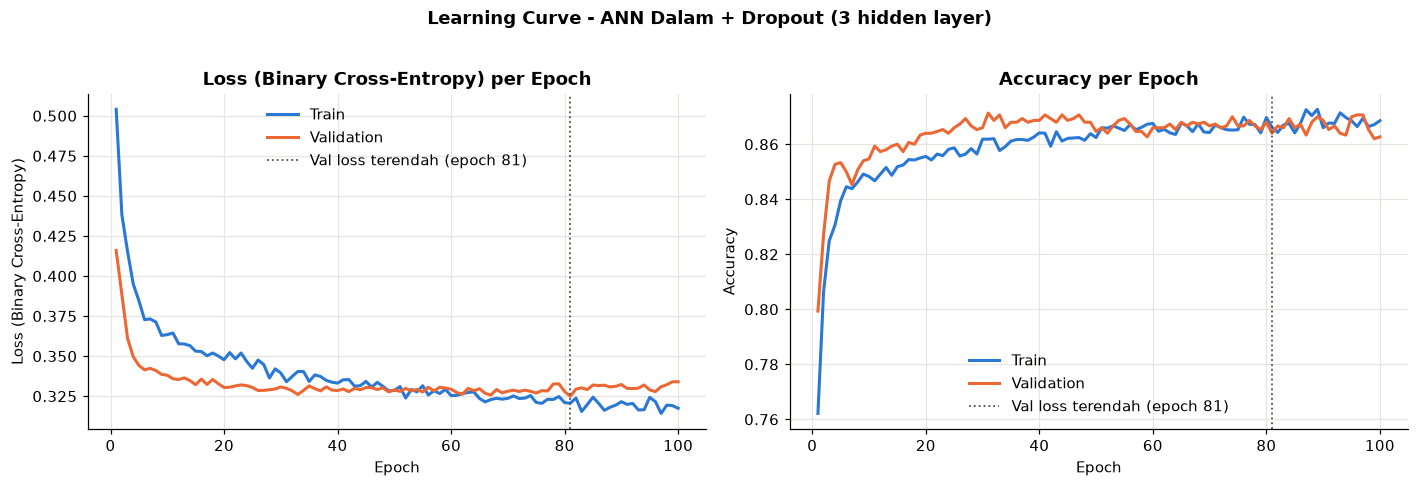

[ANN Dalam + Dropout (3 hidden layer)]
  Epoch terakhir (100): train loss = 0.3174 | val loss = 0.3340 | selisih (val - train) = +0.0165
                       train acc  = 0.8686 | val acc  = 0.8627
  Val loss terendah = 0.3249 pada epoch 81; kenaikan val loss sesudahnya = +0.0090


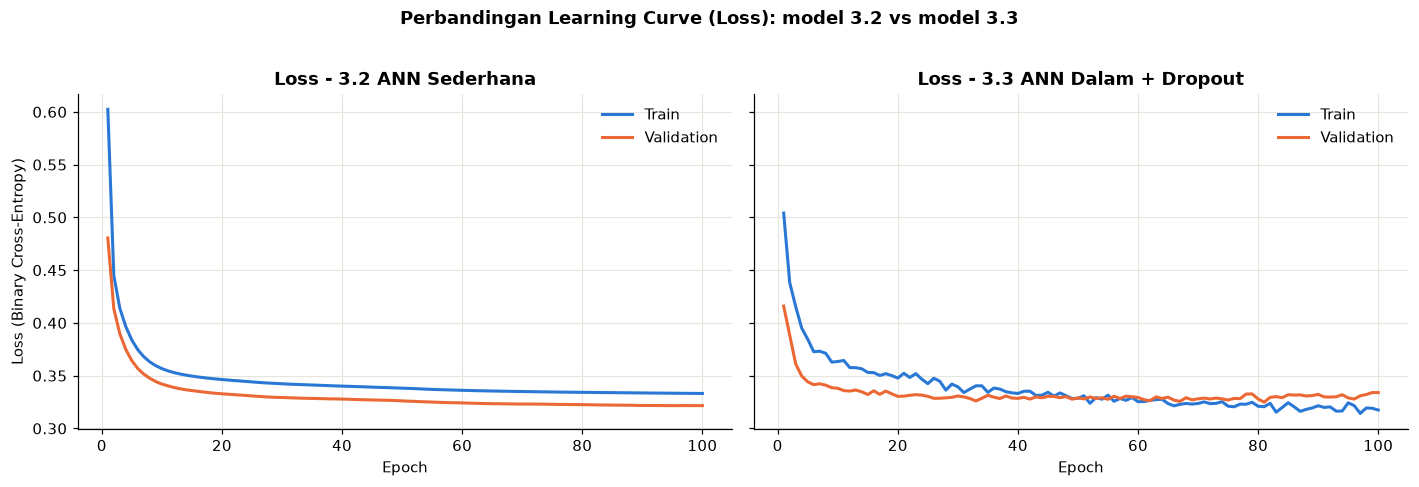

Loss tanpa Dropout (model.evaluate) pada akhir training:
  3.2 ANN Sederhana       : train loss = 0.3318 (acc 0.8626) | val loss = 0.3217 (acc 0.8687) | selisih = -0.0102
  3.3 ANN Dalam + Dropout : train loss = 0.2916 (acc 0.8791) | val loss = 0.3340 (acc 0.8627) | selisih = +0.0424


In [27]:
# Latih model dengan cara yang sama seperti 3.2, lalu tampilkan learning curve train vs validation.
# Bandingkan bentuk learning curve-nya dengan model 3.2. Apakah ada tanda overfitting?
model_dalam.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)
history_dalam = model_dalam.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=0,
)
histories["ANN Dalam + Dropout"] = history_dalam
tampilkan_log(history_dalam)

plot_learning_curve(history_dalam, "ANN Dalam + Dropout (3 hidden layer)")

# Perbandingan langsung dengan model 3.2 pada sumbu yang sama
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), sharey=True)
for ax, (nama, h) in zip(axes, [("3.2 ANN Sederhana", history), ("3.3 ANN Dalam + Dropout", history_dalam)]):
    ep = np.arange(1, len(h.history["loss"]) + 1)
    ax.plot(ep, h.history["loss"], color=WARNA_TRAIN, linewidth=2, label="Train")
    ax.plot(ep, h.history["val_loss"], color=WARNA_VAL, linewidth=2, label="Validation")
    ax.set_title(f"Loss - {nama}")
    ax.set_xlabel("Epoch")
    ax.legend()
axes[0].set_ylabel("Loss (Binary Cross-Entropy)")
fig.suptitle("Perbandingan Learning Curve (Loss): model 3.2 vs model 3.3", fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

# Catatan: train loss model 3.3 dihitung saat Dropout AKTIF, sedangkan val loss dihitung saat Dropout NONAKTIF.
# Agar adil, train loss dihitung ulang tanpa Dropout dengan model.evaluate().
print("Loss tanpa Dropout (model.evaluate) pada akhir training:")
for nama, m in [("3.2 ANN Sederhana", model_sederhana), ("3.3 ANN Dalam + Dropout", model_dalam)]:
    tr = m.evaluate(X_train, y_train, verbose=0)
    va = m.evaluate(X_val, y_val, verbose=0)
    print(f"  {nama:24s}: train loss = {tr[0]:.4f} (acc {tr[1]:.4f}) | val loss = {va[0]:.4f} (acc {va[1]:.4f}) "
          f"| selisih = {va[0] - tr[0]:+.4f}")

**Jawaban: apakah ada tanda overfitting pada model 3.3?**

Ya, ada tanda **overfitting ringan**, sedangkan model 3.2 tidak menunjukkannya.

- **Model 3.2 (ANN sederhana):** train loss dan validation loss turun bersama-sama dengan mulus dan mendatar di akhir (train 0,3332; validation 0,3217). Validation loss terendah baru tercapai pada epoch 96, artinya sampai akhir training kurva validation belum berbalik naik.
- **Model 3.3 (ANN dalam + Dropout):** validation loss mencapai titik terendah 0,3248 pada **epoch 33**, setelah itu mendatar dan cenderung naik sampai 0,3306 pada epoch 100, padahal train loss terus turun (0,3394 pada epoch 30 → 0,3166 pada epoch 100). Kurva train dan validation berpotongan lalu saling menjauh.
- Jika train loss dihitung ulang tanpa Dropout (`model.evaluate`), selisihnya lebih jelas: train 0,2913 vs validation 0,3306 (selisih +0,039; akurasi train 0,8806 vs validation 0,8667). Pada model 3.2 selisih yang sama hanya −0,010.
- Pada epoch-epoch awal model 3.3, train loss justru lebih tinggi daripada validation loss. Ini bukan underfitting, melainkan efek Dropout: train loss dihitung saat sebagian neuron dimatikan, sedangkan validation loss dihitung dengan seluruh neuron aktif.

Overfitting-nya tergolong ringan (validation loss hanya naik 0,006 dari titik terendah), tetapi sudah cukup untuk menunjukkan bahwa kapasitas tambahan dipakai untuk menghafal train set, bukan untuk generalisasi.

In [28]:
# Lakukan prediksi pada test set.
# Simpan hasil prediksi label dan probabilitas kelas 1 untuk keperluan evaluasi.
y_prob_dalam = model_dalam.predict(X_test, verbose=0).ravel()
y_pred_dalam = (y_prob_dalam >= 0.5).astype(int)
hasil["ANN Dalam + Dropout"] = {"y_pred": y_pred_dalam, "y_prob": y_prob_dalam}

print(f"Akurasi test: {accuracy_score(y_test, y_pred_dalam):.4f}")
print(f"Jumlah prediksi churn pada test set: {int(y_pred_dalam.sum())} dari {len(y_pred_dalam)} (aktual churn: {int(y_test.sum())})")

Akurasi test: 0.8647
Jumlah prediksi churn pada test set: 188 dari 1500 (aktual churn: 305)


## 3.4 Penanganan Data Imbalanced

Pada data imbalanced, model cenderung lebih sering memprediksi kelas mayoritas sehingga recall kelas churn rendah. Salah satu cara mengatasinya adalah dengan memberi bobot lebih besar pada kelas minoritas di loss function.

In [29]:
# Gunakan arsitektur terbaik dari 3.2 atau 3.3 (buat ulang modelnya agar bobot mulai dari awal), lalu latih dengan class weight.
# Hitung bobot setiap kelas berdasarkan train set, misalnya dengan sklearn.utils.class_weight.compute_class_weight("balanced", ...).
# Masukkan ke model.fit() melalui parameter class_weight={0: bobot_kelas_0, 1: bobot_kelas_1}.

# 1) Pilih arsitektur terbaik dari 3.2 / 3.3 berdasarkan VALIDATION set
#    (test set tidak boleh dipakai untuk mengambil keputusan desain model).
kandidat = {"ANN Sederhana": (model_sederhana, build_ann_sederhana),
            "ANN Dalam + Dropout": (model_dalam, build_ann_dalam)}
baris_val = []
for nama, (m, _) in kandidat.items():
    prob_val = m.predict(X_val, verbose=0).ravel()
    pred_val = (prob_val >= 0.5).astype(int)
    baris_val.append({"model": nama, "val_loss": m.evaluate(X_val, y_val, verbose=0)[0],
                      "val_accuracy": accuracy_score(y_val, pred_val),
                      "val_f1": f1_score(y_val, pred_val), "val_auc": roc_auc_score(y_val, prob_val)})
perbandingan_val = pd.DataFrame(baris_val).set_index("model")
print("Performa pada validation set:")
display(perbandingan_val)

nama_terbaik = perbandingan_val["val_auc"].idxmax()
build_terbaik = kandidat[nama_terbaik][1]
print(f"Arsitektur terbaik (val AUC tertinggi): {nama_terbaik}\n")

# 2) Hitung class weight dari train set: w_k = n_sampel / (n_kelas x n_sampel_kelas_k)
bobot = compute_class_weight(class_weight="balanced", classes=np.array([0, 1]), y=y_train.astype(int))
class_weight = {0: float(bobot[0]), 1: float(bobot[1])}
print(f"Bobot kelas 0 (bertahan): {class_weight[0]:.4f}")
print(f"Bobot kelas 1 (churn)   : {class_weight[1]:.4f}")
print(f"=> Kesalahan pada 1 nasabah churn dihitung {class_weight[1] / class_weight[0]:.2f}x lebih berat daripada 1 nasabah bertahan.\n")

# 3) Buat ulang model (bobot mulai dari awal) lalu latih dengan class weight
tf.keras.utils.set_random_seed(SEED)
model_cw = build_terbaik(n_features)
model_cw.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)
# Validation loss ikut diberi bobot yang sama (sample_weight) supaya kurva loss train dan validation
# berada pada skala yang sama dan bisa dibandingkan. Accuracy tetap tidak berbobot.
sw_val = np.where(y_val == 1, class_weight[1], class_weight[0]).astype("float32")
history_cw = model_cw.fit(
    X_train, y_train,
    validation_data=(X_val, y_val, sw_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    class_weight=class_weight,
    verbose=0,
)
histories["ANN + Class Weight"] = history_cw
print(f"Model '{model_cw.name}' selesai dilatih ulang dengan class weight.")
tampilkan_log(history_cw)

Performa pada validation set:


,val_loss,val_accuracy,val_f1,val_auc
model,,,,
ANN Sederhana,0.3217,0.8687,0.6020,0.8797
ANN Dalam + Dropout,0.3340,0.8627,0.5847,0.8668


Arsitektur terbaik (val AUC tertinggi): ANN Sederhana

Bobot kelas 0 (bertahan): 0.6279
Bobot kelas 1 (churn)   : 2.4544
=> Kesalahan pada 1 nasabah churn dihitung 3.91x lebih berat daripada 1 nasabah bertahan.

Model 'ANN_Sederhana' selesai dilatih ulang dengan class weight.


,accuracy,loss,val_accuracy,val_loss
epoch,,,,
1,0.5074,0.7138,0.7013,0.6167
10,0.7597,0.4820,0.7773,0.4561
20,0.7746,0.4686,0.7860,0.4468
30,0.7839,0.4620,0.7920,0.4418
40,0.7883,0.4570,0.8007,0.4367
50,0.7919,0.4534,0.8060,0.4334
60,0.7937,0.4507,0.8060,0.4325
70,0.7937,0.4489,0.8113,0.4324
80,0.7944,0.4475,0.8113,0.4325


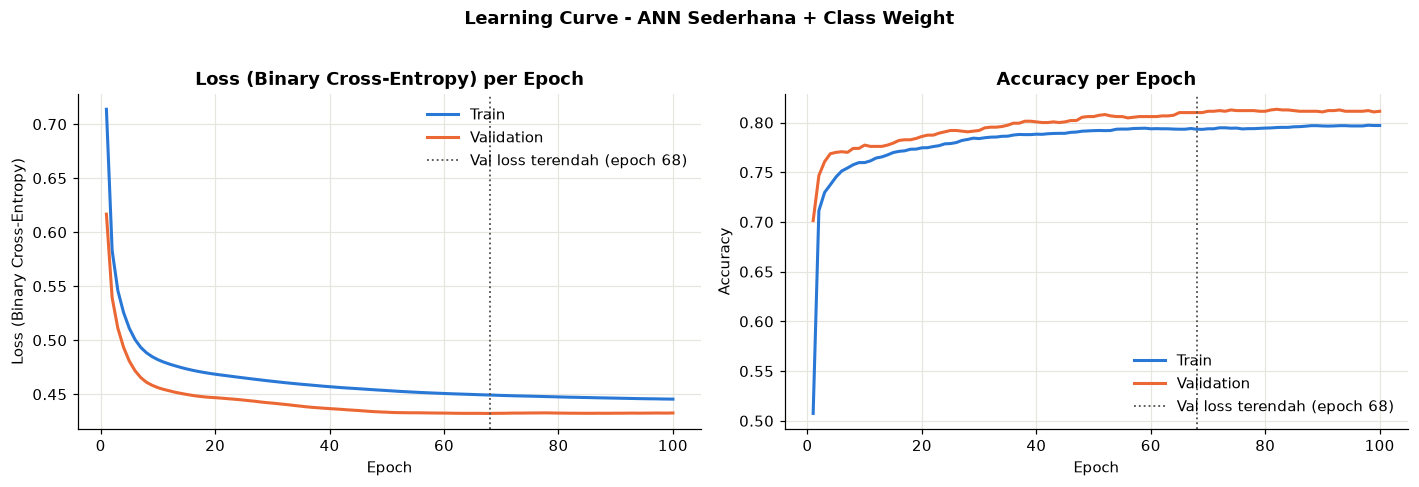

[ANN Sederhana + Class Weight]
  Epoch terakhir (100): train loss = 0.4455 | val loss = 0.4327 | selisih (val - train) = -0.0128
                       train acc  = 0.7970 | val acc  = 0.8113
  Val loss terendah = 0.4322 pada epoch 68; kenaikan val loss sesudahnya = +0.0004
  (loss di atas adalah loss BERBOBOT, sehingga skalanya tidak sama dengan loss model 3.2 dan 3.3)

Akurasi test: 0.7967
Jumlah prediksi churn pada test set: 450 dari 1500 (aktual churn: 305)


In [30]:
# Tampilkan learning curve train vs validation.
# Lakukan prediksi pada test set, simpan hasil prediksi label dan probabilitas kelas 1.
plot_learning_curve(history_cw, f"{nama_terbaik} + Class Weight")
print("  (loss di atas adalah loss BERBOBOT, sehingga skalanya tidak sama dengan loss model 3.2 dan 3.3)")

y_prob_cw = model_cw.predict(X_test, verbose=0).ravel()
y_pred_cw = (y_prob_cw >= 0.5).astype(int)
hasil["ANN + Class Weight"] = {"y_pred": y_pred_cw, "y_prob": y_prob_cw}

print(f"\nAkurasi test: {accuracy_score(y_test, y_pred_cw):.4f}")
print(f"Jumlah prediksi churn pada test set: {int(y_pred_cw.sum())} dari {len(y_pred_cw)} (aktual churn: {int(y_test.sum())})")

# 4. Evaluasi Model

In [31]:
# Tampilkan metrik evaluasi untuk setiap model: Accuracy, Precision, Recall, dan F1-Score.
# Sajikan dalam satu tabel perbandingan agar mudah dibandingkan.

# Precision, Recall, dan F1 dihitung untuk kelas positif = churn (Exited = 1).
y_true = y_test.astype(int)
baris = []
for nama, h in hasil.items():
    baris.append({
        "Model": nama,
        "Accuracy": accuracy_score(y_true, h["y_pred"]),
        "Precision": precision_score(y_true, h["y_pred"], zero_division=0),
        "Recall": recall_score(y_true, h["y_pred"]),
        "F1-Score": f1_score(y_true, h["y_pred"]),
        "ROC-AUC": roc_auc_score(y_true, h["y_prob"]),
    })
tabel_evaluasi = pd.DataFrame(baris).set_index("Model")

print(f"Perbandingan metrik evaluasi pada TEST set ({len(y_true)} nasabah, {int(y_true.sum())} churn), threshold 0.5")
print("Sel berwarna paling gelap = nilai terbaik pada kolom tersebut.")
display(tabel_evaluasi.style.format("{:.4f}").background_gradient(cmap="Blues", axis=0))

print(f"\nPembanding: model naif (selalu menebak 'bertahan') -> accuracy {1 - y_true.mean():.4f}, recall 0.0000")

Perbandingan metrik evaluasi pada TEST set (1500 nasabah, 305 churn), threshold 0.5
Sel berwarna paling gelap = nilai terbaik pada kolom tersebut.


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Logistic Regression,0.8153,0.6458,0.2033,0.3092,0.7913
ANN Sederhana,0.8693,0.7884,0.4885,0.6032,0.8653
ANN Dalam + Dropout,0.8647,0.7713,0.4754,0.5882,0.8657
ANN + Class Weight,0.7967,0.5000,0.7377,0.5960,0.8671



Pembanding: model naif (selalu menebak 'bertahan') -> accuracy 0.7967, recall 0.0000


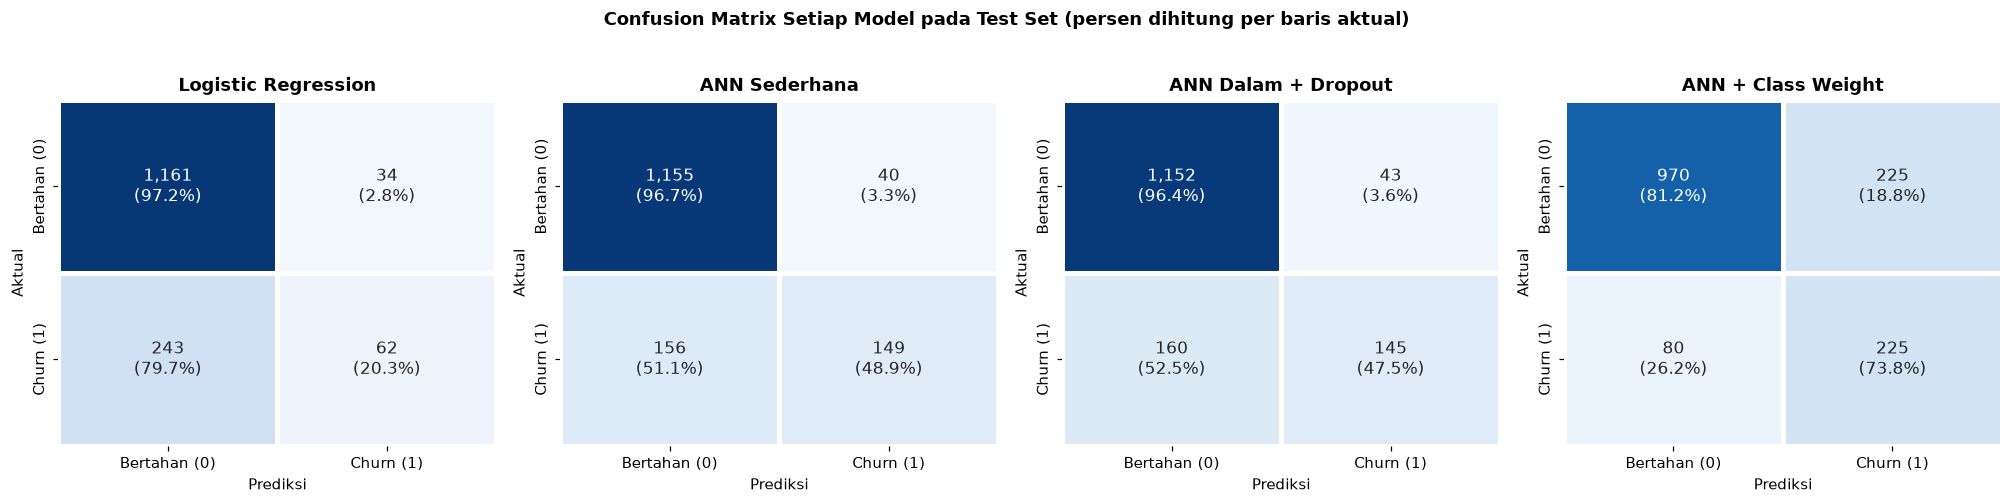

,TN,FP,FN,TP,Churn terdeteksi,Alarm palsu
Model,,,,,,
Logistic Regression,1161,34,243,62,62 dari 305,34 dari 1195
ANN Sederhana,1155,40,156,149,149 dari 305,40 dari 1195
ANN Dalam + Dropout,1152,43,160,145,145 dari 305,43 dari 1195
ANN + Class Weight,970,225,80,225,225 dari 305,225 dari 1195


In [32]:
# Tampilkan Confusion Matrix setiap model dalam bentuk heatmap.
# Susun dalam satu baris subplot.
fig, axes = plt.subplots(1, len(hasil), figsize=(4.6 * len(hasil), 4.4))
for ax, (nama, h) in zip(axes, hasil.items()):
    cm = confusion_matrix(y_true, h["y_pred"])
    cm_persen = cm / cm.sum(axis=1, keepdims=True) * 100      # persen terhadap jumlah aktual (per baris)
    anotasi = np.array([[f"{cm[i, j]:,}\n({cm_persen[i, j]:.1f}%)" for j in range(2)] for i in range(2)])
    sns.heatmap(cm, annot=anotasi, fmt="", cmap="Blues", cbar=False, vmin=0, vmax=cm.sum(axis=1).max(),
                linewidths=2, linecolor="white", annot_kws={"fontsize": 11},
                xticklabels=["Bertahan (0)", "Churn (1)"], yticklabels=["Bertahan (0)", "Churn (1)"], ax=ax)
    ax.set_title(nama)
    ax.set_xlabel("Prediksi")
    ax.set_ylabel("Aktual")
    ax.grid(False)
fig.suptitle("Confusion Matrix Setiap Model pada Test Set (persen dihitung per baris aktual)",
             fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

rincian = []
for nama, h in hasil.items():
    tn, fp, fn, tp = confusion_matrix(y_true, h["y_pred"]).ravel()
    rincian.append({"Model": nama, "TN": tn, "FP": fp, "FN": fn, "TP": tp,
                    "Churn terdeteksi": f"{tp} dari {tp + fn}", "Alarm palsu": f"{fp} dari {tn + fp}"})
display(pd.DataFrame(rincian).set_index("Model"))

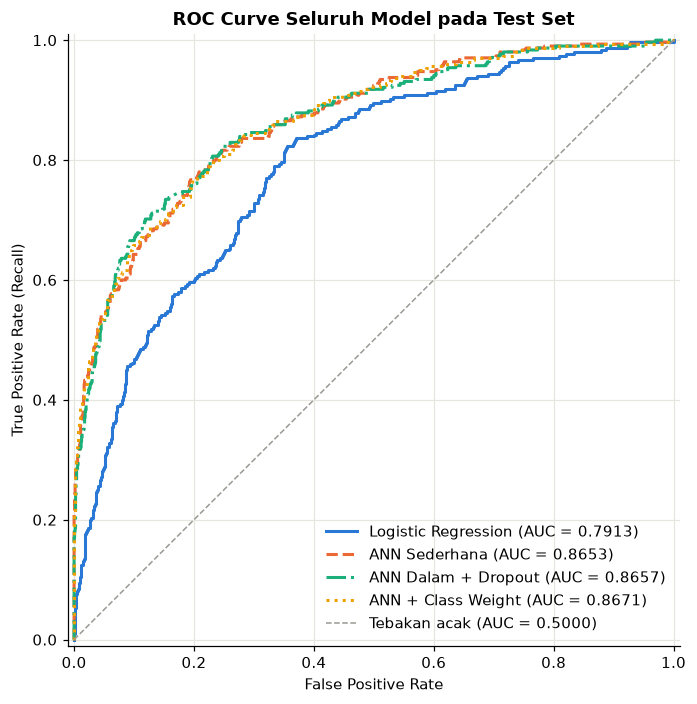

Nilai AUC (diurutkan):


,ROC-AUC
Model,
ANN + Class Weight,0.8671
ANN Dalam + Dropout,0.8657
ANN Sederhana,0.8653
Logistic Regression,0.7913


In [33]:
# Tampilkan ROC Curve seluruh model dalam satu plot beserta nilai AUC masing-masing.

WARNA_MODEL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
GAYA_GARIS = ["-", "--", "-.", ":"]      # gaya garis berbeda agar model tetap bisa dibedakan tanpa warna

fig, ax = plt.subplots(figsize=(7.5, 6.5))
for (nama, h), warna, gaya in zip(hasil.items(), WARNA_MODEL, GAYA_GARIS):
    fpr, tpr, _ = roc_curve(y_true, h["y_prob"])
    auc = roc_auc_score(y_true, h["y_prob"])
    ax.plot(fpr, tpr, color=warna, linestyle=gaya, linewidth=2, label=f"{nama} (AUC = {auc:.4f})")
ax.plot([0, 1], [0, 1], color="#9a9992", linestyle="--", linewidth=1, label="Tebakan acak (AUC = 0.5000)")
ax.set_title("ROC Curve Seluruh Model pada Test Set")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate (Recall)")
ax.set_xlim(-0.01, 1.01); ax.set_ylim(-0.01, 1.01)
ax.set_aspect("equal")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

print("Nilai AUC (diurutkan):")
display(tabel_evaluasi["ROC-AUC"].sort_values(ascending=False).to_frame())

# 5. Analisis

### Jelaskan secara detail hasil analisis yang didapatkan dari eksperimen yang telah dilakukan. Bandingkan performa Logistic Regression dan setiap konfigurasi ANN berdasarkan hasil evaluasi. Bahas pula bentuk learning curve masing-masing model (overfitting/underfitting), pengaruh penambahan layer dan Dropout, serta pengaruh class weight terhadap precision dan recall kelas churn. Pastikan analisis didasari oleh hasil eksperimen sendiri yang telah dilakukan.

## Hasil Analisis

Seluruh angka di bawah ini diambil dari output eksperimen di atas (test set: 1.500 nasabah, 305 di antaranya churn; threshold 0,5; precision, recall, dan F1 dihitung untuk kelas churn).

| Model | Accuracy | Precision | Recall | F1-Score | ROC-AUC | TP | FP | FN |
|---|---|---|---|---|---|---|---|---|
| Logistic Regression | 0,8153 | 0,6458 | 0,2033 | 0,3092 | 0,7913 | 62 | 34 | 243 |
| ANN Sederhana (16) | **0,8693** | **0,7884** | 0,4885 | **0,6032** | 0,8653 | 149 | 40 | 156 |
| ANN Dalam + Dropout (64-32-16) | 0,8653 | 0,7668 | 0,4852 | 0,5944 | 0,8647 | 148 | 45 | 157 |
| ANN Sederhana + Class Weight | 0,7980 | 0,5022 | **0,7410** | 0,5987 | **0,8670** | 226 | 224 | 79 |

### a. Logistic Regression vs ANN

- **Logistic Regression tertinggal jauh.** Akurasinya 0,8153, hanya 1,9 poin di atas model naif yang selalu menebak "bertahan" (0,7967). Recall-nya 0,2033: dari 305 nasabah churn hanya **62 yang terdeteksi**, 243 lolos. Model ini hanya memprediksi churn untuk 96 nasabah, jauh di bawah jumlah churn sebenarnya.
- **ANN sederhana memperbaiki semua metrik sekaligus.** Hanya dengan satu hidden layer berisi 16 neuron (225 parameter), akurasi naik menjadi 0,8693, recall menjadi 0,4885 (149 terdeteksi, 2,4 kali Logistic Regression), precision naik dari 0,6458 ke 0,7884, dan F1 hampir dua kali lipat (0,3092 → 0,6032). Alarm palsu hanya bertambah 6 (34 → 40).
- **Perbedaannya bukan sekadar soal threshold.** AUC mengukur kemampuan mengurutkan nasabah berdasarkan risiko tanpa bergantung pada threshold, dan nilainya naik dari 0,7913 ke sekitar 0,865 untuk semua ANN. Pada ROC curve, kurva Logistic Regression berada di bawah ketiga kurva ANN hampir di sepanjang sumbu.
- **Penyebabnya konsisten dengan temuan EDA.** Logistic Regression hanya bisa membuat batas keputusan linear, sedangkan dua sinyal terkuat di data ini tidak linear: proporsi churn terhadap usia naik lalu turun, dan terhadap `NumOfProducts` berbentuk U (27,7% → 7,6% → 82,7% → 100%). Hal ini terlihat pada koefisien Logistic Regression untuk `NumOfProducts` yang hampir nol (−0,03) padahal fitur tersebut sangat informatif. Hidden layer dengan aktivasi ReLU dapat membentuk pola non-linear dan interaksi antar fitur tersebut.
- Sesuai prinsip di bagian 3.1, ANN **layak digunakan** pada kasus ini karena performanya jelas lebih baik daripada baseline.

### b. Bentuk learning curve (overfitting / underfitting)

| Model | Train loss akhir | Val loss akhir | Val loss terendah | Epoch val loss terendah | Train acc | Val acc |
|---|---|---|---|---|---|---|
| ANN Sederhana | 0,3332 | 0,3217 | 0,3216 | 96 | 0,8600 | 0,8687 |
| ANN Dalam + Dropout | 0,3166 | 0,3306 | 0,3248 | 33 | 0,8690 | 0,8667 |
| ANN + Class Weight (loss berbobot) | 0,4454 | 0,4326 | 0,4323 | 89 | 0,7984 | 0,8087 |

- **ANN sederhana - good fit.** Kedua kurva turun cepat pada 10 epoch pertama (val loss 0,4805 → 0,3421), lalu melandai dan berjalan sejajar sampai akhir. Validation loss tidak pernah berbalik naik dan titik terendahnya ada di epoch 96, sehingga **tidak ada overfitting**. Model juga **tidak underfitting**: akurasi train 0,86 jauh di atas baseline dan loss sudah mendatar (val loss hanya turun 0,0008 dari epoch 80 ke 100), artinya training lebih lama tidak akan banyak membantu. Validation loss sedikit lebih rendah daripada train loss; selisihnya kecil (0,01) dan wajar untuk validation set berukuran 1.500 baris.
- **ANN dalam + Dropout - overfitting ringan.** Validation loss terendah tercapai jauh lebih awal (epoch 33), lalu mendatar dan naik perlahan ke 0,3306, sementara train loss terus turun sampai 0,3166. Bila train loss dihitung tanpa Dropout, selisihnya lebih jelas: 0,2913 (train) vs 0,3306 (validation), dengan akurasi train 0,8806 vs validation 0,8667. Kurva validation-nya juga lebih bergerigi dibanding model sederhana.
- **ANN + class weight - good fit, tetapi pada skala loss yang berbeda.** Bentuk kurvanya mirip ANN sederhana (turun bersama, mendatar, tidak berbalik naik). Loss-nya lebih tinggi (sekitar 0,44) karena kesalahan pada kelas churn dikalikan bobot 2,45, sehingga angka loss-nya tidak bisa dibandingkan langsung dengan dua model lain. Akurasi train dan validation (0,80 dan 0,81) lebih rendah karena model sengaja digeser untuk lebih sering menebak churn.

### c. Pengaruh penambahan layer dan Dropout

- **Menambah layer tidak meningkatkan performa.** Model 3.3 memiliki 3.457 parameter (15,4 kali model 3.2), tetapi hasil test-nya sedikit lebih rendah: F1 0,5944 vs 0,6032, AUC 0,8647 vs 0,8653, akurasi 0,8653 vs 0,8693. Pada validation set hasilnya searah (AUC 0,8704 vs 0,8797; val loss 0,3306 vs 0,3217), sehingga arsitektur sederhana yang dipilih untuk bagian 3.4.
- **Selisihnya sangat kecil.** Kedua model hanya berbeda 1 nasabah churn yang terdeteksi (149 vs 148) dan 5 alarm palsu (40 vs 45). Dengan satu kali training dan test set berisi 305 churn, selisih sekecil ini masih dalam rentang variasi acak. Kesimpulan yang aman adalah **kedua model setara**, bukan bahwa model dalam lebih buruk.
- **Mengapa tidak membantu?** Dataset ini kecil dan berbentuk tabular (7.000 baris train, 12 fitur). Pola yang ada sudah bisa ditangkap oleh 16 neuron, sehingga kapasitas tambahan tidak menemukan pola baru dan malah mulai menghafal train set.
- **Peran Dropout.** Dropout 0,3 menahan overfitting sehingga tetap ringan: walaupun parameternya 15 kali lebih banyak, validation loss hanya naik 0,006 dari titik terendahnya dan performa test tidak anjlok. Efek Dropout juga terlihat pada epoch awal, ketika train loss lebih tinggi daripada validation loss. Namun Dropout tidak cukup untuk menghilangkan overfitting sepenuhnya pada training 100 epoch. Perlu dicatat bahwa eksperimen ini tidak melatih model dalam tanpa Dropout, sehingga besar efek Dropout secara terpisah tidak terukur langsung.

### d. Pengaruh class weight terhadap precision dan recall kelas churn

Bobot kelas dari train set adalah 0,6279 (bertahan) dan 2,4544 (churn), sehingga satu kesalahan pada nasabah churn dihitung 3,91 kali lebih berat. Dibandingkan ANN sederhana tanpa class weight:

| Metrik | Tanpa class weight | Dengan class weight | Perubahan |
|---|---|---|---|
| Recall | 0,4885 | 0,7410 | naik 25,3 poin |
| Precision | 0,7884 | 0,5022 | turun 28,6 poin |
| F1-Score | 0,6032 | 0,5987 | hampir sama |
| Accuracy | 0,8693 | 0,7980 | turun 7,1 poin |
| ROC-AUC | 0,8653 | 0,8670 | hampir sama |
| Churn terdeteksi (TP) | 149 dari 305 | 226 dari 305 | +77 |
| Churn yang lolos (FN) | 156 | 79 | berkurang separuh |
| Alarm palsu (FP) | 40 | 224 | 5,6 kali lipat |

- **Recall naik tajam, precision turun tajam.** Model kini menangkap 74% nasabah churn (sebelumnya 49%), tetapi dari 450 nasabah yang diprediksi churn hanya sekitar separuhnya yang benar. Model memprediksi churn jauh lebih banyak (450) daripada jumlah sebenarnya (305).
- **Accuracy turun ke 0,7980**, setara dengan model naif (0,7967). Ini contoh nyata bahwa akurasi menyesatkan pada data imbalanced: model yang paling berguna untuk menemukan nasabah churn justru terlihat paling buruk dari sisi akurasi.
- **AUC dan F1 hampir tidak berubah.** Artinya class weight **tidak membuat model lebih pintar membedakan** nasabah churn dan bertahan, melainkan **menggeser titik operasi** di sepanjang kurva ROC yang sama ke arah recall lebih tinggi. Tabel threshold mendukung hal ini: ANN sederhana tanpa class weight pada threshold 0,3 menghasilkan precision 0,605 dan recall 0,662 (F1 0,632), sedangkan model class weight pada threshold 0,7 menghasilkan precision 0,687 dan recall 0,590 (F1 0,635). Kedua pendekatan bisa mencapai trade-off yang serupa.
- **Mana yang lebih baik bergantung pada biaya kesalahan.** Jika kehilangan nasabah jauh lebih mahal daripada biaya menghubungi nasabah yang sebenarnya tidak akan churn (misalnya program retensi berbiaya rendah), model dengan class weight lebih sesuai. Jika setiap tindakan retensi mahal dan harus tepat sasaran, ANN sederhana tanpa class weight lebih sesuai karena 79% prediksinya benar.

### e. Keterbatasan eksperimen

- Setiap model hanya dilatih satu kali dengan satu seed dan satu pembagian data, sehingga selisih kecil antar ANN (di bawah sekitar 1 poin) belum bisa dianggap signifikan.
- Semua metrik memakai threshold tetap 0,5, padahal threshold terbaik berbeda untuk setiap model.
- Training memakai jumlah epoch tetap (100) tanpa EarlyStopping, sehingga model 3.3 dievaluasi pada kondisi sudah melewati titik validation terbaiknya (epoch 33).

# 6. Kesimpulan dan Saran

### Berikan kesimpulan dari eksperimen yang telah dilakukan. Saran dapat berupa rekomendasi untuk eksperimen selanjutnya, perbaikan model, atau hal-hal lain yang relevan dengan tugas ini.

## Kesimpulan
Berdasarkan hasil eksperimen, Artificial Neural Network (ANN) menunjukkan performa yang lebih baik dibandingkan Logistic Regression dalam memprediksi churn nasabah. ANN sederhana berhasil meningkatkan nilai F1-score kelas churn dari 0,3092 menjadi 0,6032, recall dari 0,2033 menjadi 0,4885, serta AUC dari 0,7913 menjadi 0,8653. Sementara itu, Logistic Regression hanya mampu mendeteksi 62 dari 305 nasabah churn karena kurang mampu menangkap hubungan non-linear pada fitur Age dan NumOfProducts.

Hasil eksperimen juga menunjukkan bahwa arsitektur ANN yang sederhana sudah mampu memberikan performa optimal. ANN dengan satu hidden layer berisi 16 neuron dan 225 parameter menghasilkan accuracy sebesar 0,8693, precision sebesar 0,7884, serta F1-score sebesar 0,6032. Selain itu, learning curve menunjukkan proses pelatihan yang stabil tanpa indikasi overfitting. Penambahan kedalaman arsitektur menjadi tiga hidden layer dengan Dropout dan 3.457 parameter tidak memberikan peningkatan performa yang berarti, dengan F1-score sebesar 0,5944 dan AUC sebesar 0,8647. Model tersebut bahkan mulai menunjukkan overfitting ringan sejak epoch ke-33. Meskipun Dropout mampu menjaga overfitting tetap kecil, teknik ini belum sepenuhnya menghilangkannya.

Penerapan class weight terbukti meningkatkan recall dari 0,4885 menjadi 0,7410, sehingga jumlah nasabah churn yang berhasil terdeteksi meningkat dari 149 menjadi 226. Namun, peningkatan tersebut diikuti penurunan precision dari 0,7884 menjadi 0,5022, yang menyebabkan jumlah false positive meningkat dari 40 menjadi 224. Nilai F1-score dan AUC yang relatif tidak berubah menunjukkan bahwa class weight lebih berpengaruh terhadap titik operasi model dalam menentukan prediksi dibandingkan meningkatkan kemampuan model dalam membedakan kelas. Hal ini juga memperlihatkan bahwa accuracy bukan satu-satunya metrik yang dapat diandalkan pada dataset imbalanced, karena model dengan recall tertinggi hanya menghasilkan accuracy sebesar 0,7980, hampir sama dengan model naif sebesar 0,7967. Oleh karena itu, pemilihan model perlu mempertimbangkan precision, recall, F1-score, dan AUC sesuai kebutuhan prediksi. Secara keseluruhan, ANN sederhana dengan class weight lebih direkomendasikan apabila tujuan utama adalah mendeteksi sebanyak mungkin nasabah yang berpotensi churn, sedangkan ANN sederhana tanpa class weight lebih sesuai apabila prioritasnya adalah menghasilkan prediksi yang lebih tepat dengan jumlah alarm palsu yang lebih sedikit.

## Saran
Untuk pengembangan eksperimen selanjutnya, optimasi threshold dapat dilakukan menggunakan validation set dengan memanfaatkan precision-recall curve agar nilai threshold dapat disesuaikan dengan biaya false positive dan false negative, alih-alih selalu menggunakan threshold default sebesar 0,5. Berdasarkan hasil pengujian, ANN sederhana mampu mencapai F1-score sekitar 0,63 pada threshold 0,3–0,4. Selain itu, penggunaan EarlyStopping dan ModelCheckpoint disarankan untuk menghentikan proses pelatihan ketika validation loss tidak lagi membaik sekaligus menyimpan bobot model terbaik, terutama pada arsitektur yang lebih dalam karena performa terbaiknya diperoleh pada epoch ke-33, bukan epoch ke-100.

Eksperimen juga perlu dilakukan secara berulang menggunakan beberapa random seed atau stratified k-fold cross-validation untuk memperoleh hasil yang lebih konsisten melalui perhitungan rata-rata dan simpangan baku. Optimasi hyperparameter dapat dikembangkan dengan menguji variasi jumlah neuron, dropout rate, learning rate, batch size, serta teknik regularisasi seperti L2 dan Batch Normalization secara sistematis, misalnya menggunakan Keras Tuner. Model dengan arsitektur lebih dalam tanpa Dropout juga perlu diuji sebagai pembanding untuk mengetahui pengaruh penggunaan Dropout terhadap performa model secara langsung.

Dari sisi pengolahan data, feature engineering dapat dilakukan dengan menambahkan fitur berdasarkan hasil Exploratory Data Analysis (EDA), seperti penanda saldo nol, pengelompokan usia, mengubah NumOfProducts menjadi fitur kategorikal menggunakan one-hot encoding, serta menghitung rasio Balance terhadap EstimatedSalary. Penanganan class imbalance juga dapat dikembangkan dengan membandingkan class weight terhadap metode oversampling seperti SMOTE, undersampling, maupun focal loss, dengan menambahkan PR-AUC sebagai metrik evaluasi.

Selain ANN dan Logistic Regression, penelitian selanjutnya disarankan untuk membandingkan performa model dengan algoritma berbasis pohon seperti Random Forest, XGBoost, dan LightGBM yang berpotensi memberikan hasil kompetitif pada data tabular. Terakhir, interpretabilitas model dapat ditingkatkan menggunakan permutation importance atau SHAP untuk mengidentifikasi fitur-fitur yang paling berpengaruh terhadap prediksi churn. Dengan demikian, hasil prediksi tidak hanya dapat digunakan untuk mengidentifikasi nasabah yang berpotensi churn, tetapi juga menjadi dasar dalam merancang strategi retensi nasabah yang lebih tepat sasaran.